# The wire medium: strong spatial dispersion with no magnetism

Notebooks 02 to 04 studied rods whose axis is perpendicular to the wave vector. Spatial dispersion there was a correction of order $(ka)^2$, and the question was what part of it is a permeability. A lattice of thin metal wires with the wave vector allowed a component $\beta$ along the wires is the opposite case. Its permittivity along the wires, $\varepsilon_{zz}(\omega,\mathbf k)=1-k_p^2/(k_0^2-\beta^2)$ (Belov et al. 2003), depends on $\beta$ at first order in $\beta^2/k_0^2$ at *any* ratio of period to wavelength. For perfectly conducting wires its expansion in $\beta$ has radius of convergence $k_0$, not $1/a$: the local plasma description is accurate only to $(\beta/k_0)^2$ and fails once $\beta$ is not small against $k_0$, including the TEM waves at $\beta=k_0$, however long the wavelength is (for Drude wires the pole moves outward, section 4). That no local uniaxial $(\varepsilon,\mu)$ description reproduces the modes follows from counting modes at the printed points (section 3). The nonlocality is not a magnetic effect: it sits in the direction along the wires, where the structure of the magnetic term of notebook 01 (its $zz$ entry contains only $\mathbf k_\perp$, for any $\mu$ tensor) forbids a permeability, and the $k_\perp^2$ coefficient is not a permeability either once $\beta\neq0$ (section 2). This notebook computes it in a thin-wire multiple-scattering model (order $m=0$ only), validates the model against the multipole solver at $\beta=0$ and against Belov's and Silveirinha's formulas, and asks when metal wires of finite conductivity lose the nonlocality.

## What this notebook shows

- A thin-wire model with an exact wire-surface impedance, built on the lattice sums of `rodlattice.py` continued to imaginary $k_t=\sqrt{k_0^2-\beta^2}$, and its checks: the lattice sums against brute force, a real $\varepsilon_{zz}$ for lossless wires, the averaged-Maxwell formula against a 3 by 3 linear solve, the plasma wave number $k_p$ of the model against Belov's formula with its constant identified in closed form, Silveirinha's formula for metal wires, and the permittivity at $\beta=0$ against the full multipole solver `rodlattice.driven`.
- $\varepsilon_{zz}$ as a function of $\beta$: the pole at $\beta=k_0$, Taylor coefficients in $\beta^2$ at one frequency, and second-order coefficients in $k_\perp^2$ and $\beta^2$ at five frequencies, and the full-tensor test of whether either can be a permeability.
- The exact Bloch modes in the $(\beta,k_0)$ plane: a TEM branch $k_0=\beta$ for every $k_\perp$ and the plasma-like TM branch, against Belov's model and against the local plasma model, and a mode count, at two values of $k_0$ and one $\mathbf k_\perp$, that no local uniaxial $(\varepsilon,\mu)$ can match.
- Drude wires: how the term from the wire's kinetic inductance competes with the one that carries the $\beta$ dependence, as a function of $r_0/\delta_s$ and of $\beta/k_0$.

## Conventions

As in the other notebooks: $e^{-i\omega t}$, $\varepsilon_0=\mu_0=c=1$ so $\omega=k_0$, lengths in units of the period $a$, $f=a/\lambda_0=k_0/2\pi$ (always a frequency). The wires lie along $z$ and form a square lattice. The wave vector is $\mathbf k=(\mathbf k_\perp,\beta)$ with $\mathbf k_\perp$ in the lattice plane, $k_t=\sqrt{k_0^2-\beta^2}$ (imaginary for $\beta>k_0$) and $E$ is along the wires (TM with respect to the axis). $r_0$ is the wire radius, $\eta_w=\pi r_0^2/a^2$ its filling fraction. Drude wires have $\varepsilon_m=1-f_p^2/[f(f+if_\gamma)]$ with $f_p=a/\lambda_p$ and skin depth $\delta_s=\lambda_p/2\pi$, so $r_0/\delta_s=2\pi f_pr_0$ (with $a=1$). Wire parameters are $r_0=0.01\,a$ unless stated.

In [1]:
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ.setdefault(_v, "4")  # keep the machine usable; must run before numpy is imported

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from cycler import cycler

# Figure style shared by every notebook in notebooks/spatial_dispersion (do not edit per notebook).
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]  # series colors, fixed order
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list(  # magnitudes: one hue, light to dark
    "seq_blue", ["#eef4fc", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list(  # signed quantities: blue, neutral gray, red; use symmetric limits
    "div_blue_red", ["#0d366b", "#256abf", "#6da7ec", "#f0efec", "#ee8f8e", "#d03b3b", "#7d1919"])
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "figure.figsize": (6.4, 4.0),
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "axes.titlesize": 10, "axes.labelsize": 10,
    "legend.fontsize": 9, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": cycler(color=CAT), "lines.linewidth": 1.6, "lines.markersize": 5.5,
    "legend.frameon": False, "image.origin": "lower", "image.interpolation": "nearest", "image.cmap": "seq_blue",
    "figure.constrained_layout.use": True,
})
plt.colormaps.register(SEQ, force=True)
plt.colormaps.register(DIV, force=True)


def check(name, value, tol, target=0.0):
    """Print PASS or FAIL for |value - target| <= tol and assert it, so a rerun catches regressions."""
    err = abs(value - target)
    print(f"{'PASS' if err <= tol else 'FAIL'}  {name}: got {value:.6g}, target {target:.6g}, |diff| {err:.2e} <= {tol:.0e}")
    assert err <= tol, name

In [2]:
import sys, pathlib, time
sys.path.insert(0, str(pathlib.Path.cwd()))          # rodlattice.py and wires.py sit next to this notebook
import rodlattice as rl
import wires as w
from scipy.special import jv, gamma, hankel1
from scipy.optimize import brentq

TWO_PI = 2 * np.pi
R0 = 0.01
T0 = time.perf_counter()

## 1. The thin-wire model and its checks

**Model.** Each wire carries a current $I\,e^{i(\mathbf k_\perp\cdot\mathbf R_j+\beta z)}$ spread uniformly on a cylindrical surface of radius $r_0\ll a$ (order $m=0$ only). Maxwell's equations with the charge density of that current in the divergence term give, outside the wire, $(\nabla_\perp^2+k_t^2)E_z=-i(k_t^2/k_0)J_z$, so one wire produces

$$E_z=-\frac{k_t^2}{4k_0}\,I\,J_0(k_tr_0)\,H_0(k_t\rho).$$

The external source is $J_0\hat z\,e^{i\mathbf k\cdot\mathbf r}$, which fills all space. Without wires it produces $E_z^{\rm ext}=i(k_t^2/k_0)J_0/(k_\perp^2-k_t^2)$; the printed 3 by 3 check below verifies this against the full vector equation. The condition on wire 0 is that the surface average of the total $E_z$ equals $Z_wI$. Its own field contributes $J_0(k_tr_0)H_0(k_tr_0)$, the other wires $J_0(k_tr_0)^2G_0$ with $G_0=G_0(k_t,\mathbf k_\perp)$ the lattice sum of `rodlattice.lattice_sums`, and the source $J_0(k_\perp r_0)$ (the surface average of $e^{i\mathbf k_\perp\cdot\boldsymbol\rho}$):

$$I\Big[Z_w+\frac{k_t^2}{4k_0}J_0(k_tr_0)\big(H_0(k_tr_0)+J_0(k_tr_0)G_0\big)\Big]=\frac{i k_t^2}{k_0(k_\perp^2-k_t^2)}J_0(k_\perp r_0)\,J_0^{\rm src}.$$

Every factor is that of a uniform surface current, so filament and surface forms are never mixed (a prototype that mixed them returned a spurious imaginary part of $2\times10^{-5}$ for lossless wires). The macroscopic polarization is $P_z=(i/k_0)\langle J\rangle$ with $\langle J\rangle=I\,J_0(k_\perp r_0)/a^2$ (the same surface average, as form factor), and the averaged Maxwell equation $(k^2-k_0^2)\mathbf E-\mathbf k(\mathbf k\cdot\mathbf E)=k_0^2\mathbf P+ik_0\mathbf J$ gives $E_z=(k_t^2/k_0^2)(k_0^2P_z+ik_0J_0)/(k_\perp^2-k_t^2)$ (the in-plane components of $\mathbf E$ are eliminated with the transverse part of the equation; the 3 by 3 check below does it without that step). Then $\varepsilon=\mathrm{diag}(1,1,\varepsilon_{zz})$ with $\varepsilon_{zz}=1+P_z/E_z$.

**Wire impedance.** For uniform current in a thin metal wire $J=\sigma E$ with $\sigma=-ik_0(\varepsilon_m-1)$ (the polarization current $-i\omega P$), and $I=\pi r_0^2\sigma E$, so $Z_w=i/[k_0(\varepsilon_m-1)\pi r_0^2]$. For a solid round wire $E_z\propto J_0(k_m\rho)$ inside, $k_m=k_0\sqrt{\varepsilon_m}$, and the total current is $I=\sigma E_s\,2\pi r_0J_1(k_mr_0)/[k_mJ_0(k_mr_0)]$, so $Z_w=k_mJ_0(k_mr_0)/[2\pi r_0\sigma J_1(k_mr_0)]$, which tends to the thin form for $|k_mr_0|\ll1$ (printed below). This exact form ignores $\beta^2$ against $k_m^2$ inside the metal and takes the field outside to depend on the total current only, both fine for $k_tr_0\ll1$ and $|\varepsilon_m|\gg1$. Every result below says which impedance it uses: perfect conductor ($Z_w=0$), thin, or exact.

**A closed form.** Writing $G_0=-4i/[a^2(k_\perp^2-k_t^2)]+G_{\rm reg}$ (the $\mathbf G=0$ plane wave plus a regular part) and using $J_0\to1$, the equations above reduce, for a perfect conductor, to

$$\varepsilon_{zz}-1=\frac{4i}{k_t^2a^2\,[H_0(k_tr_0)+G_{\rm reg}]},$$

in which the sum $H_0+G_{\rm reg}$ tends to a constant, $-4i/(a^2k_p^2)$, as the wave numbers go to zero. That defines the $k_p$ of the model; and with a wire impedance the bracket gains $4k_0Z_w/k_t^2$, which gives Silveirinha's form $\varepsilon_{zz}=1+1/[T-k_t^2/k_p^2]$ with kinetic term $T=-ia^2k_0Z_w$ ($=1/[(\varepsilon_m-1)\eta_w]$ for the thin impedance). Those two statements are derived here and checked numerically below.

**Real form for modes.** The mode condition is $D\equiv Z_w+\frac{k_t^2}{4k_0}J_0(k_tr_0)[H_0(k_tr_0)+J_0(k_tr_0)G_0]=0$. For real $k_t$ below the diffraction onset $G_0=-1+iN_0$ with real $N_0$ (checked below), so $H_0+J_0G_0=i(Y_0+J_0N_0)$ is imaginary; for imaginary $k_t$ all three terms are imaginary as well. With $q=k_\perp^2-k_t^2$, the pole of $G_0$ at $q=0$ is removed by $qD$, and `wires.mode_function` $=\mathrm{Re}\,[qD/i]$ changes sign only at modes. For a perfect conductor $k_t^2$ is a factor of $D$, so $\beta=k_0$ is a zero for every $k_\perp$ (the TEM line, section 3).

### 1(a) Lattice sums at imaginary $k_t$ and the real form

In [3]:
print("(a) lattice sums at imaginary k_t against brute force (nmax = 60), and the real forms")
worst = 0.0
for k0, beta, kp in [(0.314, 0.6, (0.3, 0.2)), (0.314, 1.0, (0.0, 0.0001)), (0.5, 3.0, (1.2, 0.4)), (1.0, 1.9, (2.0, 2.0))]:
    kt = w.kt_of(k0, beta)
    G = rl.lattice_sums(kt, kp, 2)
    D = rl.direct_lattice_sums(kt, kp, 2, nmax=60)
    err = np.abs(G - D).max() / np.abs(D).max()
    worst = max(worst, err)
    print(f"    k0 = {k0}, beta = {beta}, k_t = {kt:.4f}, k_perp = {kp}: relative difference {err:.1e}")
check("(a) lattice sums at imaginary k_t against brute force (relative)", worst, 1e-10)

wr, wi = 0.0, 0.0
for kt, kp in [(0.3, (0.1, 0.0)), (1.1, (1.0, 0.3)), (2.5, (0.5, 0.2)), (3.5, (2.5, 0.0)), (2 * np.pi * 0.3, (1.0, 0.3))]:
    G0 = w.G0_of(kt, kp)
    wr = max(wr, abs(G0.real + 1))
for k0, beta, kp in [(0.3, 1.0, (1.0, 0.3)), (1.0, 2.0, (0.5, 0.2)), (0.3, 3.0, (2.0, 2.0))]:
    G0 = w.G0_of(w.kt_of(k0, beta), kp)
    wi = max(wi, abs(G0.real))
check("(a) real k_t below diffraction onset: Re G_0 = -1", wr, 1e-10)
check("(a) imaginary k_t: G_0 is purely imaginary", wi, 1e-10)

(a) lattice sums at imaginary k_t against brute force (nmax = 60), and the real forms
    k0 = 0.314, beta = 0.6, k_t = 0.0000+0.5113j, k_perp = (0.3, 0.2): relative difference 8.3e-15
    k0 = 0.314, beta = 1.0, k_t = 0.0000+0.9494j, k_perp = (0.0, 0.0001): relative difference 4.5e-15
    k0 = 0.5, beta = 3.0, k_t = 0.0000+2.9580j, k_perp = (1.2, 0.4): relative difference 1.1e-15
    k0 = 1.0, beta = 1.9, k_t = 0.0000+1.6155j, k_perp = (2.0, 2.0): relative difference 1.2e-15
PASS  (a) lattice sums at imaginary k_t against brute force (relative): got 8.28411e-15, target 0, |diff| 8.28e-15 <= 1e-10
PASS  (a) real k_t below diffraction onset: Re G_0 = -1: got 4.44089e-15, target 0, |diff| 4.44e-15 <= 1e-10
PASS  (a) imaginary k_t: G_0 is purely imaginary: got 4.26428e-17, target 0, |diff| 4.26e-17 <= 1e-10


### 1(b) Real $\varepsilon_{zz}$ for lossless wires; the averaged Maxwell equation by a 3 by 3 solve

In [4]:
cases = [(0.05, (0.1, 0.0), 0.0), (0.05, (0.3, 0.2), 0.1), (0.1, (0.4, 0.0), 0.2), (0.3, (1.0, 0.3), 0.5),
         (0.05, (0.3, 0.2), 0.6), (0.05, (0.0001, 0.0), 0.9), (0.1, (2.0, 1.0), 2.0), (0.2, (0.5, 0.0), 1.2)]
worst = 0.0
print("(b) lossless wires: eps_zz (perfect conductor, thin impedance with real eps_m, exact impedance with real eps_m)")
for f, kp, beta in cases:
    k0 = TWO_PI * f
    es = [w.eps_zz(k0, kp, beta, R0), w.eps_zz(k0, kp, beta, R0, -3000.0), w.eps_zz(k0, kp, beta, R0, -3000.0, exact=True)]
    worst = max(worst, max(abs(e.imag) / abs(e) for e in es))
    print(f"    f = {f}, k_perp = {kp}, beta = {beta}: {es[0].real: .6f}  {es[1].real: .6f}  {es[2].real: .6f}")
check("(b) lossless wires give a real eps_zz (max |Im|/|eps|)", worst, 1e-10)

rng = np.random.default_rng(3)
worst = 0.0
for _ in range(5):
    k0 = rng.uniform(0.1, 2.0)
    kv = rng.uniform(-1.5, 1.5, 3)
    Pz = complex(rng.normal(), rng.normal())
    k2 = kv @ kv
    A = (k2 - k0**2) * np.eye(3) - np.outer(kv, kv)
    rhs = np.array([0, 0, k0**2 * Pz + 1j * k0])
    Ez = np.linalg.solve(A.astype(complex), rhs)[2]
    kt2 = k0**2 - kv[2] ** 2
    kp2 = kv[0] ** 2 + kv[1] ** 2
    formula = (kt2 / k0**2) * (k0**2 * Pz + 1j * k0) / (kp2 - kt2)
    worst = max(worst, abs(Ez / formula - 1))
check("(b) E_z of the averaged Maxwell equation: formula against a 3 by 3 solve (relative)", worst, 1e-12)

# the closed form eps_zz - 1 = 4i / (k_t^2 a^2 (H_0 + G_reg)) against the full solution
worst = 0.0
for f, kp, beta in cases:
    k0 = TWO_PI * f
    kt = w.kt_of(k0, beta)
    kp2 = kp[0] ** 2 + kp[1] ** 2
    Greg = w.G0_of(kt, kp) - 4j / (kt**2 - kp2)
    # J_0 factors are not dropped in eps_zz, so compare at tiny r0 where they equal one to 1e-9
    r = 1e-5
    full = w.eps_zz(k0, kp, beta, r)
    closed = 1 + 4j / (kt**2 * (hankel1(0, kt * r) + Greg))
    worst = max(worst, abs(full / closed - 1))
check("(b) closed form eps_zz - 1 = 4i / (k_t^2 a^2 (H_0 + G_reg)) against the full solution (relative)", worst, 1e-8)

(b) lossless wires: eps_zz (perfect conductor, thin impedance with real eps_m, exact impedance with real eps_m)
    f = 0.05, k_perp = (0.1, 0.0), beta = 0.0: -18.305654   0.101106   0.104263
    f = 0.05, k_perp = (0.3, 0.2), beta = 0.1: -20.464604   0.096882   0.100068
    f = 0.1, k_perp = (0.4, 0.0), beta = 0.2: -4.354265   0.198368   0.208285
    f = 0.3, k_perp = (1.0, 0.3), beta = 0.5:  0.443273   0.649976   0.665820
    f = 0.05, k_perp = (0.3, 0.2), beta = 0.6:  8.304668  -0.082500  -0.077925
    f = 0.05, k_perp = (0.0001, 0.0), beta = 0.9:  3.694700  -0.450157  -0.441958
    f = 0.1, k_perp = (2.0, 1.0), beta = 2.0:  1.526610   2.193328   2.216008
    f = 0.2, k_perp = (0.5, 0.0), beta = 1.2: -12.665410   0.118065   0.163514
PASS  (b) lossless wires give a real eps_zz (max |Im|/|eps|): got 1.52971e-14, target 0, |diff| 1.53e-14 <= 1e-10
PASS  (b) E_z of the averaged Maxwell equation: formula against a 3 by 3 solve (relative): got 6.81677e-14, target 0, |diff| 6.82e-14 <= 1e-

### 1(c) The plasma wave number of the model against Belov's formula

For a perfect conductor and $k_0,\beta,k_\perp\to0$, $\varepsilon_{zz}-1\to-k_p^2/(k_0^2-\beta^2)$. `wires.kp2_model` extracts $k_p^2$ exactly from that limit (the value is the same at $k=10^{-3}$ and $10^{-2}$ to $10^{-6}$). Belov's formula is $k_p^2=2\pi/[a^2(\ln(a/2\pi r_0)+0.5275)]$. Writing the model's value as $2\pi/k_p^2=\ln(a/2\pi r_0)+c$ shows the constant $c$ the model implies; $H_0(k_tr_0)$ differs from its small-argument form by $O(r_0^2\ln r_0)$, so $c$ should become independent of $r_0$ as $r_0\to0$. The square-lattice constant is also known in terms of the Dedekind eta function at $\tau=i$, $c=-2\ln\eta(i)=\ln[4\pi^{3/2}/\Gamma(1/4)^2]$; this is used here as an independent value to compare with (it is recalled, not derived, and the comparison is what tests it).

In [5]:
print("(c) k_p^2 of the model against Belov (c = 0.5275), and the implied constant c")
rows = []
for r in [0.1, 0.03, 0.01, 0.003, 0.001, 0.0003]:
    m, b = w.kp2_model(r), w.kp2_belov(r)
    c = TWO_PI / m - np.log(1 / (TWO_PI * r))
    rows.append((r, m, b, c))
    print(f"    r0 = {r:<7}: k_p a model {np.sqrt(m):.6f}   Belov {np.sqrt(b):.6f}   relative difference of k_p^2 {m / b - 1: .2e}   implied c = {c:.6f}")
c_eta = np.log(4 * np.pi**1.5 / gamma(0.25) ** 2)
print(f"    c from the eta-function form: {c_eta:.6f}")
m01 = w.kp2_model(0.01)
check("(c) k_p^2 independent of the extraction wave number (relative)", w.kp2_model(0.01, k=1e-2) / m01 - 1, 1e-5)
check("(c) k_p^2 at r0 = 0.01, model against Belov (relative)", m01 / w.kp2_belov(0.01) - 1, 1e-4)
check("(c) constant c as r0 -> 0 against the eta-function value", rows[-1][3], 2e-5, target=c_eta)
check("(c) constant c as r0 -> 0 against Belov's 0.5275", rows[-1][3], 3e-4, target=0.5275)
print(f"    headline: k_p a at r0 = 0.01: model {np.sqrt(m01):.5f}, Belov {np.sqrt(w.kp2_belov(0.01)):.5f}, so f_p = a/lambda_p = {np.sqrt(m01) / TWO_PI:.5f}")

(c) k_p^2 of the model against Belov (c = 0.5275), and the implied constant c
    r0 = 0.1    : k_p a model 2.477723   Belov 2.516452   relative difference of k_p^2 -3.05e-02   implied c = 0.558760
    r0 = 0.03   : k_p a model 1.690409   Belov 1.691437   relative difference of k_p^2 -1.21e-03   implied c = 0.530172
    r0 = 0.01   : k_p a model 1.380910   Belov 1.380943   relative difference of k_p^2 -4.80e-05   implied c = 0.527658
    r0 = 0.003  : k_p a model 1.181815   Belov 1.181798   relative difference of k_p^2  2.84e-05   implied c = 0.527372
    r0 = 0.001  : k_p a model 1.059506   Belov 1.059492   relative difference of k_p^2  2.73e-05   implied c = 0.527347
    r0 = 0.0003 : k_p a model 0.961164   Belov 0.961153   relative difference of k_p^2  2.29e-05   implied c = 0.527344
    c from the eta-function form: 0.527344
PASS  (c) k_p^2 independent of the extraction wave number (relative): got -6.97085e-07, target 0, |diff| 6.97e-07 <= 1e-05
PASS  (c) k_p^2 at r0 = 0.01, model 

### 1(d) Silveirinha's formula for metal wires, and the two impedances

For metal wires $\varepsilon_{zz}=1+1/[T-(k_0^2-\beta^2)/k_p^2]$ with $T=1/[(\varepsilon_m-1)\eta_w]$ (thin impedance) or $T=-ia^2k_0Z_w$ with the exact one. The comparison is against the full model with the same impedance, at a low frequency where the formula should hold up to the $(k_0a)^2$ corrections that its constant $k_p$ lacks.

In [6]:
print("(d) thin-wire model against Silveirinha's form, f = 0.05, k_perp = (0.2, 0.1), beta = 0.15, r0 = 0.01")
f, kp, beta = 0.05, (0.2, 0.1), 0.15
k0 = TWO_PI * f
kp2m = w.kp2_model(R0)
worst_t, worst_e = 0.0, 0.0
for em in [-1e4, -300.0, -30.0, -3.0]:
    e_t, e_e = w.eps_zz(k0, kp, beta, R0, em), w.eps_zz(k0, kp, beta, R0, em, exact=True)
    s_t, s_e = w.eps_silveirinha(k0, beta, R0, em, kp2m), w.eps_silveirinha(k0, beta, R0, em, kp2m, exact=True)
    worst_t, worst_e = max(worst_t, abs(e_t / s_t - 1)), max(worst_e, abs(e_e / s_e - 1))
    print(f"    eps_m = {em:>8}: thin model {e_t.real: .6f}  formula {s_t.real: .6f} (rel {abs(e_t / s_t - 1):.1e});  exact Z_w model {e_e.real: .6f}  formula {s_e.real: .6f} (rel {abs(e_e / s_e - 1):.1e});  Z_w exact / thin = {w.Zw_exact(k0, R0, em) / w.Zw_thin(k0, R0, em):.5f}")
check("(d) thin impedance: model against Silveirinha's formula (relative, worst of 4)", worst_t, 5e-4)
check("(d) exact impedance: model against the generalized formula (relative, worst of 4)", worst_e, 5e-4)
check("(d) exact impedance tends to the thin form for |k_m r0| << 1 (|ratio - 1|, eps_m = -3)", abs(w.Zw_exact(k0, R0, -3.0) / w.Zw_thin(k0, R0, -3.0) - 1), 1e-5)

(d) thin-wire model against Silveirinha's form, f = 0.05, k_perp = (0.2, 0.1), beta = 0.15, r0 = 0.01
    eps_m = -10000.0: thin model -1.791161  formula -1.791457 (rel 1.7e-04);  exact Z_w model -1.761024  formula -1.761314 (rel 1.6e-04);  Z_w exact / thin = 1.01229+0.00000j
    eps_m =   -300.0: thin model  0.905795  formula  0.905794 (rel 6.2e-07);  exact Z_w model  0.905829  formula  0.905829 (rel 6.2e-07);  Z_w exact / thin = 1.00037+0.00000j
    eps_m =    -30.0: thin model  0.990265  formula  0.990265 (rel 2.8e-08);  exact Z_w model  0.990265  formula  0.990265 (rel 2.8e-08);  Z_w exact / thin = 1.00004+0.00000j
    eps_m =     -3.0: thin model  0.998743  formula  0.998743 (rel 3.2e-09);  exact Z_w model  0.998743  formula  0.998743 (rel 3.2e-09);  Z_w exact / thin = 1.00000+0.00000j
PASS  (d) thin impedance: model against Silveirinha's formula (relative, worst of 4): got 0.000165415, target 0, |diff| 1.65e-04 <= 5e-04
PASS  (d) exact impedance: model against the generalized for

### 1(e) $\beta=0$: against the full multipole solver

At $\beta=0$ the wires are the TM problem of notebook 03: rods of radius $R$ with a large negative permittivity, solved with all multipoles by `rodlattice.driven`. The thin-wire model keeps only $m=0$ on a surface current, so the difference should shrink with $R$. (The $m=\pm1$ response is absent from the thin-wire model; its identification as the wires' eddy-current diamagnetism is the likely reading, not tested separately; a second cell below measures what it does to the $k_\perp^2$ coefficient and extends the comparison to larger $k_\perp$ and $R$.) The solver's rod is a solid cylinder, so the comparison uses the exact impedance (the thin one is shown to fail once $R$ is not small against the skin depth of $\varepsilon=-10^4$, which is $1/(k_0\sqrt{10^4})$).

In [7]:
print("(e) beta = 0: thin-wire model (exact impedance) against rodlattice.driven (M = 4)")
worst, rows = 0.0, []
for R, eps in [(0.02, -1e6 + 1e3j), (0.02, -1e4), (0.02, -1e3), (0.02, -50.0), (0.005, -1e4), (0.01, -300.0)]:
    for f, kv in [(0.05, (0.1, 0.0)), (0.1, (0.3, 0.2)), (0.15, (0.5, 0.5))]:
        k0 = TWO_PI * f
        d = rl.driven(k0, kv, R, eps, "TM", M=4)[0]
        t = w.eps_zz(k0, kv, 0.0, R, eps, exact=True)
        t2 = w.eps_zz(k0, kv, 0.0, R, eps)
        rows.append((R, eps, f, abs(t / d - 1), abs(t2 / d - 1)))
        if R <= 0.02:
            worst = max(worst, abs(t / d - 1))
        print(f"    R = {R}, eps = {eps}, f = {f}, k = {kv}: solver {d.real: .5f}{d.imag:+.1e}j  thin-wire {t.real: .5f}{t.imag:+.1e}j  rel {abs(t / d - 1):.1e}  (thin impedance: {abs(t2 / d - 1):.1e})")
check("(e) thin-wire (exact impedance) against the multipole solver, worst over the table (relative)", worst, 3e-3)
r_big = [r for r in rows if r[0] == 0.02 and r[1] == -1e4]
assert min(r[4] for r in r_big) > 1e-2, "the thin impedance should fail at R = 0.02, eps = -1e4"
print("    scaling with R at eps = -1e4, f = 0.1, k = (0.3, 0.2):")
Rs = [0.04, 0.02, 0.01, 0.005]
errs = []
for R in Rs:
    d = rl.driven(TWO_PI * 0.1, (0.3, 0.2), R, -1e4, "TM", M=4)[0]
    t = w.eps_zz(TWO_PI * 0.1, (0.3, 0.2), 0.0, R, -1e4, exact=True)
    errs.append(abs(t / d - 1))
    print(f"        R = {R}: relative difference {errs[-1]:.2e}")
slope = np.polyfit(np.log(Rs), np.log(errs), 1)[0]
print(f"    fitted power of R: {slope:.2f}")
assert slope > 1.8, "the difference should vanish at least like R^2"
print(f"    headline: at eps = -1e4, f = 0.1, k = (0.3, 0.2) the relative difference is {errs[1]:.1e} at R = 0.02 and {errs[-1]:.1e} at R = 0.005 (worst over the whole table at R <= 0.02: {worst:.1e})")

(e) beta = 0: thin-wire model (exact impedance) against rodlattice.driven (M = 4)
    R = 0.02, eps = (-1000000+1000j), f = 0.05, k = (0.1, 0.0): solver -21.91106+7.8e-04j  thin-wire -21.90836+7.8e-04j  rel 1.2e-04  (thin impedance: 4.8e-02)
    R = 0.02, eps = (-1000000+1000j), f = 0.1, k = (0.3, 0.2): solver -4.89936+9.5e-05j  thin-wire -4.89802+9.5e-05j  rel 2.7e-04  (thin impedance: 3.2e-02)
    R = 0.02, eps = (-1000000+1000j), f = 0.15, k = (0.5, 0.5): solver -1.62961+2.7e-05j  thin-wire -1.62770+2.7e-05j  rel 1.2e-03  (thin impedance: 2.9e-02)
    R = 0.02, eps = -10000.0, f = 0.05, k = (0.1, 0.0): solver -7.04191+2.1e-14j  thin-wire -7.04131+8.5e-15j  rel 8.5e-05  (thin impedance: 3.7e-02)
    R = 0.02, eps = -10000.0, f = 0.1, k = (0.3, 0.2): solver -2.86653+2.8e-14j  thin-wire -2.86588-5.7e-16j  rel 2.3e-04  (thin impedance: 8.1e-02)
    R = 0.02, eps = -10000.0, f = 0.15, k = (0.5, 0.5): solver -1.06914+5.8e-15j  thin-wire -1.06834-5.0e-16j  rel 7.6e-04  (thin impedance: 1.3

In [8]:
print("(e') larger k_perp and R at beta = 0, eps = -1e8 (exact impedance): relative difference thin-wire / multipole solver - 1, k along x, f = 0.05")
big = {}
for R in [0.01, 0.05, 0.1]:
    row = []
    for kx in [0.1, 1.5, 3.0]:
        k0 = TWO_PI * 0.05
        d = rl.driven(k0, (kx, 0.0), R, -1e8, "TM", M=4)[0]
        t = w.eps_zz(k0, (kx, 0.0), 0.0, R, -1e8, exact=True)
        row.append(abs(t / d - 1))
    big[R] = row
    print(f"    R = {R}: k_x = 0.1, 1.5, 3.0 (zone edge is pi = 3.14): {row[0]:.1e}, {row[1]:.1e}, {row[2]:.1e}")
check("(e') R = 0.01, k_perp up to 3.0: thin-wire against the multipole solver (relative, worst)", max(big[0.01]), 1e-2)
assert max(big[0.1]) > 5 * max(big[0.01]) and max(big[0.1]) > 2e-3, "the m = 0 error should grow with R"

print("(e'') the k_perp^2 coefficient with all multipoles against the m = 0 model (beta = 0, R = 0.01, eps = -1e8, exact impedance)")
cp = {}
for f_ in [0.05, 0.1]:
    k0 = TWO_PI * f_
    for M_ in (1, 4):
        c_ = w.taylor(lambda kx: rl.driven(k0, (kx, 0.0), R0, -1e8, "TM", M=M_)[0], 0.2, n=24, orders=range(0, 3))
        cp[f_, M_] = k0**2 * c_[2].real
    c_t = w.taylor(lambda kx: w.eps_zz(k0, (kx, 0.0), 0.0, R0, -1e8, exact=True), 0.2, n=24, orders=range(0, 3))
    cp[f_, "thin"] = k0**2 * c_t[2].real
    print(f"    f = {f_}: k0^2 c_perp: m = 0 model {cp[f_, 'thin']:.5f}, solver with M = 1 {cp[f_, 1]:.5f}, with M = 4 {cp[f_, 4]:.5f}; "
          f"model minus solver {cp[f_, 'thin'] - cp[f_, 4]:.2e} ({(cp[f_, 'thin'] / cp[f_, 4] - 1) * 100:.1f} % of the solver value); 2 eta_w = {2 * np.pi * R0**2:.2e}")
    check(f"(e'') M = 1 already contains the whole multipole effect, f = {f_} (relative)", cp[f_, 1] / cp[f_, 4] - 1, 1e-3)
    assert cp[f_, "thin"] > cp[f_, 4] > 0
print(f"    the m = 0 model overestimates k0^2 c_perp by {(cp[0.05, 'thin'] / cp[0.05, 4] - 1) * 100:.1f} % at f = 0.05; the term it lacks is the m = +-1 one (M = 1 already reproduces M = 4); that this is the wires' eddy-current diamagnetism is the likely reading, not tested separately")

(e') larger k_perp and R at beta = 0, eps = -1e8 (exact impedance): relative difference thin-wire / multipole solver - 1, k along x, f = 0.05
    R = 0.01: k_x = 0.1, 1.5, 3.0 (zone edge is pi = 3.14): 1.0e-05, 1.0e-03, 4.5e-03
    R = 0.05: k_x = 0.1, 1.5, 3.0 (zone edge is pi = 3.14): 1.4e-04, 1.7e-02, 7.6e-02
    R = 0.1: k_x = 0.1, 1.5, 3.0 (zone edge is pi = 3.14): 2.1e-03, 5.3e-02, 2.2e-01
PASS  (e') R = 0.01, k_perp up to 3.0: thin-wire against the multipole solver (relative, worst): got 0.00453669, target 0, |diff| 4.54e-03 <= 1e-02
(e'') the k_perp^2 coefficient with all multipoles against the m = 0 model (beta = 0, R = 0.01, eps = -1e8, exact impedance)
    f = 0.05: k0^2 c_perp: m = 0 model 0.01397, solver with M = 1 0.01319, with M = 4 0.01319; model minus solver 7.86e-04 (6.0 % of the solver value); 2 eta_w = 6.28e-04
PASS  (e'') M = 1 already contains the whole multipole effect, f = 0.05 (relative): got 2.50374e-09, target 0, |diff| 2.50e-09 <= 1e-03
    f = 0.1: k0^2 c_p

## 2. Spatial dispersion along the wires

Along $\beta$ at fixed frequency and $\mathbf k_\perp$ the permittivity has a pole at $\beta=\pm k_0$: the model has it, because the factor $k_t^2$ in the denominator vanishes there. For perfect wires a Taylor series in $\beta^2$ therefore converges only for $|\beta|<k_0$, whatever $k_0a$; in Belov's form the relative change $[\varepsilon_{zz}(\beta)-\varepsilon_{zz}(0)]/[\varepsilon_{zz}(0)-1]=x^2/(1-x^2)$, $x=\beta/k_0$, does not depend on $a/\lambda$ at all (the printed comparison with the model follows the figure), so the local plasma value is accurate to $x^2$ for small $\beta$ and fails for $\beta$ not small against $k_0$. The figure compares the exact $\varepsilon_{zz}(\beta)$ with Belov's form and with truncations of its Taylor series; the Taylor coefficients are Cauchy integrals over a circle of complex $\beta$ (the combination $H_0+J_0G_0$ is analytic in $k_t^2$, so complex $\beta$ is allowed), exactly as in notebook 03.

In [9]:
f2 = 0.05
k02 = TWO_PI * f2
KP0 = (0.0, 0.0)
cb = w.taylor(lambda b: w.eps_zz(k02, KP0, b, R0), 0.3 * k02, n=32, orders=range(0, 11))
cb2 = w.taylor(lambda b: w.eps_zz(k02, KP0, b, R0), 0.5 * k02, n=32, orders=range(0, 11))
print("Taylor coefficients in beta at k_perp = 0, f = 0.05 (circle of radius 0.3 k0):")
for m in range(0, 11, 2):
    print(f"    beta^{m}: {cb[m].real: .6e}   ratio to the previous even order times k0^2: {'' if m < 4 else f'{(cb[m] / cb[m - 2]).real * k02**2:.8f}'}")
odd = max(abs(cb[m]) for m in range(1, 11, 2)) / abs(cb[2])
ratios = [(cb[m] / cb[m - 2]).real * k02**2 for m in (4, 6, 8, 10)]
check("odd orders in beta vanish (relative to the beta^2 coefficient)", odd, 1e-6)
check("coefficients are real (relative)", np.abs(cb.imag).max() / abs(cb[2]), 1e-6)
check("coefficients do not depend on the radius of the circle (beta^2, relative)", cb2[2] / cb[2] - 1, 1e-6)
for m, r_ in zip((4, 6, 8, 10), ratios):
    check(f"ratio of beta^{m} to beta^{m - 2} coefficients times k0^2 is 1 (radius of convergence k0)", r_, 1e-4, target=1.0)
cbeta = cb[2].real
print(f"    c_beta k_0^2 = {cbeta * k02**2:.4f},  -k_p^2 / k_0^2 = {-w.kp2_model(R0) / k02**2:.4f}")
check("beta^2 coefficient against Belov's -k_p^2 / k_0^4 (relative)", cbeta / (-w.kp2_model(R0) / k02**4) - 1, 2e-3)

Taylor coefficients in beta at k_perp = 0, f = 0.05 (circle of radius 0.3 k0):
    beta^0: -1.830710e+01   ratio to the previous even order times k0^2: 
    beta^2: -1.957635e+02   ratio to the previous even order times k0^2: 
    beta^4: -1.983497e+03   ratio to the previous even order times k0^2: 0.99999911
    beta^6: -2.009703e+04   ratio to the previous even order times k0^2: 1.00000000
    beta^8: -2.036255e+05   ratio to the previous even order times k0^2: 1.00000000
    beta^10: -2.063157e+06   ratio to the previous even order times k0^2: 1.00000000
PASS  odd orders in beta vanish (relative to the beta^2 coefficient): got 2.19847e-08, target 0, |diff| 2.20e-08 <= 1e-06
PASS  coefficients are real (relative): got 3.07672e-07, target 0, |diff| 3.08e-07 <= 1e-06
PASS  coefficients do not depend on the radius of the circle (beta^2, relative): got -2.32806e-10-1.97828e-15j, target 0, |diff| 2.33e-10 <= 1e-06
PASS  ratio of beta^4 to beta^2 coefficients times k0^2 is 1 (radius of con

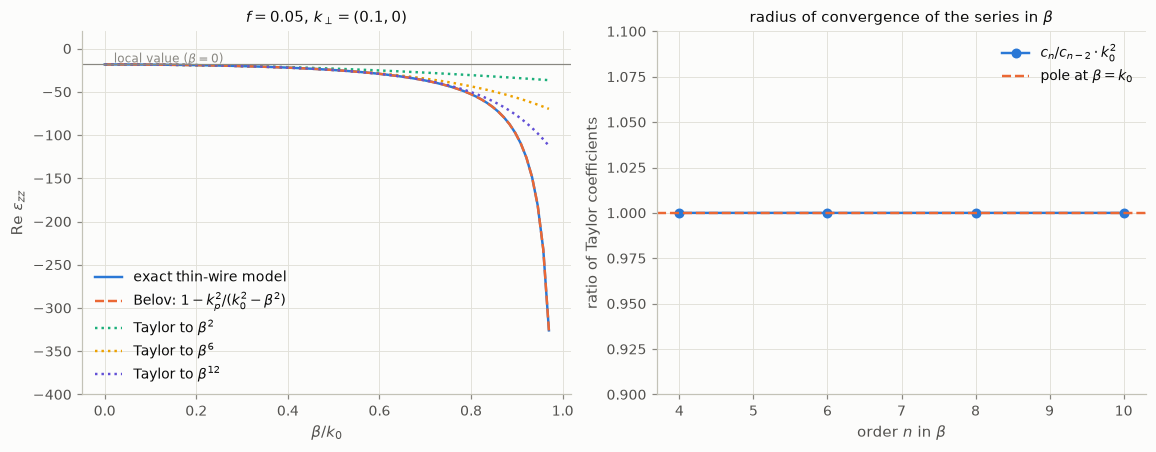

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(10.4, 4.0))
kp_plot = (0.1, 0.0)
bs = np.linspace(0, 0.97, 80) * k02
ex = np.array([w.eps_zz(k02, kp_plot, b, R0).real for b in bs])
cbp = w.taylor(lambda b: w.eps_zz(k02, kp_plot, b, R0), 0.5 * k02, n=32, orders=range(0, 13))
ax[0].plot(bs / k02, ex, color=CAT[0], label="exact thin-wire model")
ax[0].plot(bs / k02, 1 - w.kp2_belov(R0) / (k02**2 - bs**2), "--", color=CAT[1], label="Belov: $1-k_p^2/(k_0^2-\\beta^2)$")
for nmax, col in [(2, CAT[2]), (6, CAT[3]), (12, CAT[6])]:
    ts = sum(cbp[m].real * bs**m for m in range(0, nmax + 1, 2))
    ax[0].plot(bs / k02, ts, ":", color=col, label=f"Taylor to $\\beta^{{{nmax}}}$")
ax[0].axhline(ex[0], color=MUTED, lw=0.8)
ax[0].text(0.02, ex[0] * 0.92, "local value ($\\beta=0$)", color=MUTED, fontsize=8)
ax[0].set_ylim(-400, 20); ax[0].set_xlabel("$\\beta/k_0$"); ax[0].set_ylabel("Re $\\varepsilon_{zz}$")
ax[0].set_title("$f=0.05$, $k_\\perp=(0.1, 0)$"); ax[0].legend(loc="lower left")
orders = np.arange(4, 11, 2)
ax[1].plot(orders, [(cb[m] / cb[m - 2]).real * k02**2 for m in orders], "o-", color=CAT[0], label="$c_{n}/c_{n-2}\\cdot k_0^2$")
ax[1].axhline(1.0, color=CAT[1], ls="--", label="pole at $\\beta=k_0$")
ax[1].set_xlabel("order $n$ in $\\beta$"); ax[1].set_ylabel("ratio of Taylor coefficients"); ax[1].set_ylim(0.9, 1.1)
ax[1].set_title("radius of convergence of the series in $\\beta$"); ax[1].legend()
plt.show()

In [11]:
print("relative beta dependence [eps(beta) - eps(0)] / [eps(0) - 1] against x^2 / (1 - x^2), x = beta / k0 (perfect wires, k_perp = 0)")
worst_rel = 0.0
for f_, x_ in [(0.02, 0.1), (0.05, 0.1), (0.05, 0.3), (0.05, 0.5), (0.1, 0.3), (0.1, 0.5)]:
    k0_ = TWO_PI * f_
    e0_, eb_ = w.eps_zz(k0_, KP0, 0.0, R0).real, w.eps_zz(k0_, KP0, x_ * k0_, R0).real
    m_ = (eb_ - e0_) / (e0_ - 1)
    worst_rel = max(worst_rel, abs(m_ / (x_**2 / (1 - x_**2)) - 1))
    print(f"    f = {f_}, beta/k0 = {x_}: model {m_:.5f}, x^2/(1-x^2) = {x_**2 / (1 - x_**2):.5f}")
check("relative beta dependence of the model against x^2/(1-x^2) (relative, worst of 6)", worst_rel, 2e-2)

relative beta dependence [eps(beta) - eps(0)] / [eps(0) - 1] against x^2 / (1 - x^2), x = beta / k0 (perfect wires, k_perp = 0)
    f = 0.02, beta/k0 = 0.1: model 0.01010, x^2/(1-x^2) = 0.01010
    f = 0.05, beta/k0 = 0.1: model 0.01011, x^2/(1-x^2) = 0.01010
    f = 0.05, beta/k0 = 0.3: model 0.09897, x^2/(1-x^2) = 0.09890
    f = 0.05, beta/k0 = 0.5: model 0.33357, x^2/(1-x^2) = 0.33333
    f = 0.1, beta/k0 = 0.3: model 0.09919, x^2/(1-x^2) = 0.09890
    f = 0.1, beta/k0 = 0.5: model 0.33431, x^2/(1-x^2) = 0.33333
PASS  relative beta dependence of the model against x^2/(1-x^2) (relative, worst of 6): got 0.00292408, target 0, |diff| 2.92e-03 <= 2e-02


**The in-plane coefficient and what can be a permeability.** The second-order magnetic term of notebook 01 is $K^T\chi K/k_0^2$ with $\chi=1-1/\mu$, and its $zz$ entry is $(\mathbf k\times\hat z)\cdot\chi\cdot(\mathbf k\times\hat z)$. With $\mathbf k\times\hat z=(k_y,-k_x,0)$ it contains $\mathbf k_\perp$ only. So the coefficient of $\beta^2$ in $\varepsilon_{zz}$ cannot be a permeability, by structure. The coefficient of $k_\perp^2$ has the *form* of a permeability for in-plane magnetization, but only in the 2D restriction $\beta=0$; whether it is one has to be tested on the whole tensor, and the cell after the table does so. Square symmetry makes the $k_\perp^2$ coefficient isotropic. The table gives both coefficients, as $k_0^2$ times the coefficient (dimensionless, so $k_0^2c_\perp=1-1/\mu_\perp$ if the whole coefficient were a permeability) and the $\mu_\perp$ that would be implied (two digits are meaningful at most: the next cell shows that the $m=0$ model overestimates $c_\perp$ by several percent).

In [12]:
def second_order_coeffs(f, r0=R0, rho_perp=0.2):
    k0 = TWO_PI * f
    cX = w.taylor(lambda kx: w.eps_zz(k0, (kx, 0.0), 0.0, r0), rho_perp, n=24, orders=range(0, 5))
    cM = w.taylor(lambda kx: w.eps_zz(k0, (kx / np.sqrt(2), kx / np.sqrt(2)), 0.0, r0), rho_perp, n=24, orders=range(0, 5))
    cB = w.taylor(lambda b: w.eps_zz(k0, (0.0, 0.0), b, r0), 0.3 * k0, n=32, orders=range(0, 5))
    return dict(eps0=cX[0].real, perp=cX[2].real, perpM=cM[2].real, beta=cB[2].real, perp4X=cX[4].real, perp4M=cM[4].real,
                odd=max(abs(cX[1]), abs(cX[3]), abs(cB[1]), abs(cB[3])) / abs(cB[2]), k0=k0)

print("second-order coefficients of eps_zz at r0 = 0.01 (k0^2 times the coefficient)")
print("     f     eps_zz(0)    k0^2 c_perp (GX)   (GM)        k0^2 c_beta     -k_p^2/k0^2   mu_perp implied   |c_beta| / c_perp")
tab = {}
for f in [0.01, 0.02, 0.05, 0.1, 0.15]:
    c = second_order_coeffs(f)
    tab[f] = c
    k0 = c["k0"]
    print(f"  {f:5.2f}  {c['eps0']:10.3f}   {k0**2 * c['perp']:14.5f}  {k0**2 * c['perpM']:12.5f}  {k0**2 * c['beta']:12.4f}  {-w.kp2_model(R0) / k0**2:12.4f}   {1 / (1 - k0**2 * c['perp']):12.4f}   {abs(c['beta']) / c['perp']:12.1f}")
c5 = tab[0.05]
check("c_perp is isotropic at second order (GX against GM, relative)", c5["perpM"] / c5["perp"] - 1, 1e-8)
check("odd orders vanish in both variables (relative to the beta^2 coefficient)", max(t["odd"] for t in tab.values()), 1e-6)
print(f"    fourth order in k_perp at f = 0.05: GX {c5['perp4X']:.5f}, GM {c5['perp4M']:.5f} (the cos 4 phi anisotropy appears here, not at second order)")
assert abs(c5["perp4X"] - c5["perp4M"]) > 1e-3
lo, hi = tab[0.01], tab[0.1]
print(f"    k0^2 c_perp goes from {lo['k0']**2 * lo['perp']:.5f} at f = 0.01 to {hi['k0']**2 * hi['perp']:.5f} at f = 0.1, while k0^2 c_beta goes from {lo['k0']**2 * lo['beta']:.1f} to {hi['k0']**2 * hi['beta']:.2f}")
assert abs(hi["k0"] ** 2 * hi["perp"] / (lo["k0"] ** 2 * lo["perp"]) - 1) < 0.2, "k0^2 c_perp is expected to be nearly frequency independent at low f"
assert abs(lo["beta"] / hi["beta"]) / (hi["k0"] / lo["k0"]) ** 4 > 0.9, "c_beta should scale like k0^-4"
print(f"    headline at f = 0.05: c_perp = {c5['perp']:.5f} a^2, c_beta = {c5['beta']:.3f} a^2 (beta^2 coefficient / k_perp^2 coefficient = {c5['beta'] / c5['perp']:.0f})")

second-order coefficients of eps_zz at r0 = 0.01 (k0^2 times the coefficient)
     f     eps_zz(0)    k0^2 c_perp (GX)   (GM)        k0^2 c_beta     -k_p^2/k0^2   mu_perp implied   |c_beta| / c_perp
   0.01    -482.013          0.01416       0.01416     -483.0267     -483.0267         1.0144        34111.3
   0.02    -119.743          0.01417       0.01417     -120.7567     -120.7567         1.0144         8521.4
   0.05     -18.307          0.01425       0.01425      -19.3211      -19.3211         1.0145         1356.3
   0.10      -3.816          0.01452       0.01452       -4.8303       -4.8303         1.0147          332.8
   0.15      -1.133          0.01498       0.01498       -2.1469       -2.1468         1.0152          143.3
PASS  c_perp is isotropic at second order (GX against GM, relative): got 1.17306e-12, target 0, |diff| 1.17e-12 <= 1e-08
PASS  odd orders vanish in both variables (relative to the beta^2 coefficient): got 2.96381e-13, target 0, |diff| 2.96e-13 <= 1e-06
   

In [13]:
print("full-tensor test: is the k_perp^2 coefficient of eps_zz a permeability once beta != 0?")


def curl_matrix(k):
    """K_il = eps_ijl k_j, so that K v = k x v."""
    eps3 = np.zeros((3, 3, 3))
    for i_, j_, l_ in [(0, 1, 2), (1, 2, 0), (2, 0, 1)]:
        eps3[i_, j_, l_], eps3[i_, l_, j_] = 1.0, -1.0
    return np.einsum("ijl,j->il", eps3, k)


rng = np.random.default_rng(7)
worst_alg = 0.0
for _ in range(20):
    kx_, ky_, b_ = rng.normal(size=3)
    c1_, c3_ = rng.normal(size=2)
    Kq = curl_matrix(np.array([kx_, ky_, b_]))
    Mq = Kq.T @ np.diag([c1_, c1_, c3_]) @ Kq
    ref = {(2, 2): c1_ * (kx_**2 + ky_**2), (0, 0): c1_ * b_**2 + c3_ * ky_**2, (1, 1): c1_ * b_**2 + c3_ * kx_**2,
           (0, 2): -c1_ * b_ * kx_, (1, 2): -c1_ * b_ * ky_, (0, 1): -c3_ * kx_ * ky_}
    worst_alg = max(worst_alg, max(abs(Mq[i_, j_] - v_) for (i_, j_), v_ in ref.items()))
check("K^T chi K entries against the closed forms (20 random k and chi, max abs difference)", worst_alg, 1e-12)
f_t = 0.05
c5_ = second_order_coeffs(f_t)
print(f"    f = {f_t}: an in-plane mu_perp that gives c_perp = {c5_['perp']:.4f} a^2 in eps_zz needs the same coefficient c_perp in the beta^2 terms of eps_xx and eps_yy, and -c_perp beta k_x in eps_xz")
print(f"    the model has eps = diag(1, 1, eps_zz) by construction (only axial currents, so P_x = P_y = 0): those coefficients are 0, not {c5_['perp']:.4f}")
print(f"    ratio of the beta^2 coefficient of eps_zz to the required partner coefficient: {abs(c5_['beta']) / c5_['perp']:.0f}")
assert c5_["perp"] > 0 and c5_["perp"] * 1e3 > 1
print("    so the k_perp^2 coefficient is axial-current (non-magnetic) spatial dispersion that looks like a permeability only at beta = 0;")
print("    cancelling the missing partner terms would need a fine-tuned electric term of the same size, which is not a permeability either")

full-tensor test: is the k_perp^2 coefficient of eps_zz a permeability once beta != 0?
PASS  K^T chi K entries against the closed forms (20 random k and chi, max abs difference): got 8.88178e-16, target 0, |diff| 8.88e-16 <= 1e-12
    f = 0.05: an in-plane mu_perp that gives c_perp = 0.1443 a^2 in eps_zz needs the same coefficient c_perp in the beta^2 terms of eps_xx and eps_yy, and -c_perp beta k_x in eps_xz
    the model has eps = diag(1, 1, eps_zz) by construction (only axial currents, so P_x = P_y = 0): those coefficients are 0, not 0.1443
    ratio of the beta^2 coefficient of eps_zz to the required partner coefficient: 1356
    so the k_perp^2 coefficient is axial-current (non-magnetic) spatial dispersion that looks like a permeability only at beta = 0;
    cancelling the missing partner terms would need a fine-tuned electric term of the same size, which is not a permeability either


*What the table and the tensor test say.* The $\beta^2$ coefficient is the plasma term, $-k_p^2/k_0^4$ (the check above), and it is not a permeability by structure. It grows like $k_0^{-4}$ at low frequency. The $k_\perp^2$ coefficient is tiny in comparison, and the printed $k_0^2c_\perp$ is nearly constant at low frequency, which is the frequency dependence a permeability would have, with an implied $\mu_\perp-1$ of order $10^{-2}$. But the printed full-tensor test settles that it is not a permeability. By the algebra checked above, an in-plane $\mu_\perp$ with $\chi_\perp=k_0^2c_\perp$ puts $\chi_\perp\beta^2/k_0^2$ into $\varepsilon_{xx}$ and $\varepsilon_{yy}$ and $-\chi_\perp\beta k_x/k_0^2$ into $\varepsilon_{xz}$, and the model's tensor, exactly $\mathrm{diag}(1,1,\varepsilon_{zz})$, has none of them. Once $\beta\neq0$ what is left after subtracting the magnetic part is as large as that part, so the Landau-Lifshitz criterion of notebook 01 fails for it as well as for the much larger $\beta^2$ coefficient. The $k_\perp^2$ coefficient is therefore non-magnetic spatial dispersion of the axial current: an axial current that varies across cells is the curl of an in-plane magnetization only at $\beta=0$; at $\beta\neq0$ the same magnetization would also need transverse currents, which the model forbids. (Real thin wires have a transverse response only of order $\eta_w$, the size of the $m=\pm1$ correction measured in section 1(e); that this keeps the conclusion beyond the model is an expectation, not computed here.) Neither second-order coefficient of $\varepsilon_{zz}$ (in $\beta^2$ or in $k_\perp^2$) is a permeability once $\beta\neq0$ in this model, and the strong nonlocality of the wire medium is carried by the direction in which no magnetization can act.

## 3. Modes

The exact Bloch modes at fixed $\mathbf k_\perp$ are the sign changes of `wires.mode_function` on a fine grid of $k_0$ at each $\beta$, refined by bisection, below the diffraction onset (`wires.diffraction_onset`: $k_t<\min_{\mathbf G\neq0}|\mathbf k_\perp+\mathbf G|$), above which $G_0$ is complex and the real form is invalid. For perfect wires the model should give (i) the TEM line $k_0=\beta$ exactly, for every $\mathbf k_\perp$, and (ii) the plasma-like branch near $k_0^2=k_p^2+k_\perp^2+\beta^2$ (Belov's model, which follows from $k_\perp^2=k_t^2\varepsilon_{zz}$ with $\varepsilon_{zz}=1-k_p^2/k_t^2$). The comparison model is the local plasma medium $\varepsilon_{zz}=1-k_p^2/k_0^2$, $\varepsilon_\perp=1$, whose extraordinary-wave dispersion is $k_\perp^2=\varepsilon_{zz}(k_0^2-\beta^2)$, i.e. $k_0^4-k_0^2(k_p^2+\beta^2+k_\perp^2)+k_p^2\beta^2=0$.

In [14]:
kp2 = w.kp2_model(R0)
grid = np.linspace(0.05, 4.2, 330)
bgrid = np.linspace(0.0, 2.6, 27)
KP_LIST = [(0.5, 0.0), (2.5, 0.0)]


def local_branches(beta, kperp2):
    s = kp2 + beta**2 + kperp2
    d = np.sqrt(s**2 - 4 * kp2 * beta**2)
    return np.sqrt(np.array([(s - d) / 2, (s + d) / 2]))


t = time.perf_counter()
modes = {}
for kp in KP_LIST:
    modes[kp] = [w.find_modes_k0(b, kp, R0, grid) for b in bgrid]
print(f"mode scan: {time.perf_counter() - t:.1f} s")
for kp in KP_LIST:
    nroots = [len(m) for m in modes[kp]]
    print(f"    k_perp = {kp}: number of modes per beta: {sorted(set(nroots))} (up to f = {grid[-1] / TWO_PI:.2f})")

tem_err, tm_dev = 0.0, []
print("exact modes (f = k0/2 pi), TEM line, Belov TM branch, local plasma branches; k_perp = (0.5, 0), selected beta")
for kp in KP_LIST:
    kp2v = kp[0] ** 2 + kp[1] ** 2
    for b, r in zip(bgrid, modes[kp]):
        if b == 0.0:
            assert len(r) == 1
        tem = r[np.argmin(abs(r - b))] if b > 0 else None
        if tem is not None:
            tem_err = max(tem_err, abs(tem - b))
        tm = r[-1]
        tm_dev.append((kp, b, tm / np.sqrt(kp2 + kp2v + b**2) - 1))
    if kp == KP_LIST[0]:
        for b in (0.0, 0.5, 1.0, 2.0):
            i = int(np.argmin(abs(bgrid - b)))
            r = modes[kp][i]
            lb = local_branches(bgrid[i], kp2v)
            print(f"    beta = {bgrid[i]:.2f}: exact f = {np.round(r / TWO_PI, 5)}  | TEM {bgrid[i] / TWO_PI:.5f}, Belov TM {np.sqrt(kp2 + kp2v + bgrid[i]**2) / TWO_PI:.5f} | local {np.round(lb / TWO_PI, 5)}")
check("TEM line k0 = beta for every k_perp and beta (max |k0 - beta|)", tem_err, 1e-9)
dev = np.array([d for _, _, d in tm_dev])
print(f"    TM branch against sqrt(k_p^2 + k_perp^2 + beta^2): relative deviation from {dev.min():.4f} to {dev.max():.4f}")
assert abs(dev).max() < 0.03

# The branches of the local model at beta = 2, k_perp = (0.5, 0) against the exact ones
i2 = int(np.argmin(abs(bgrid - 2.0)))
ex2 = modes[KP_LIST[0]][i2]
lb2 = local_branches(bgrid[i2], KP_LIST[0][0] ** 2)
print(f"    beta = {bgrid[i2]:.2f}: exact modes at f = {np.round(ex2 / TWO_PI, 4)}, local plasma model at f = {np.round(lb2 / TWO_PI, 4)}")
assert abs(lb2[0] / ex2[0] - 1) > 0.3, "the local plasma model has a flat branch near the plasma frequency; the exact lattice has none there"
print(f"    local model: a branch at f = {lb2[0] / TWO_PI:.3f} (the plasma frequency f_p = {np.sqrt(kp2) / TWO_PI:.3f}) with no counterpart in the exact modes; exact TM mode {ex2[-1] / TWO_PI:.3f} against local {lb2[1] / TWO_PI:.3f}")

print("local plasma upper branch and Belov's TM branch against the exact TM branch (relative deviation), both k_perp")
dev_loc = {}
for kp in KP_LIST:
    kp2v = kp[0] ** 2 + kp[1] ** 2
    for b in (0.5, 1.0, 2.0, 2.6):
        i_ = int(np.argmin(abs(bgrid - b)))
        tm_ = modes[kp][i_][-1]
        dl = local_branches(bgrid[i_], kp2v)[1] / tm_ - 1
        db = np.sqrt(kp2 + kp2v + bgrid[i_]**2) / tm_ - 1
        dev_loc[kp[0], b] = dl
        print(f"    k_perp = {kp[0]}, beta = {bgrid[i_]:.2f}: local upper {dl:+.3f}, Belov {db:+.3f}")
assert min(abs(dev_loc[0.5, 1.0]), abs(dev_loc[0.5, 2.0])) > 0.1, "at small k_perp the local upper branch misses the TM branch"
assert max(abs(dev_loc[2.5, b]) for b in (0.5, 1.0, 2.0, 2.6)) < 0.03, "at k_perp = 2.5 the local upper branch follows the TM branch to 3 %"

print("mode count at fixed k0 and k_perp = (0.5, 0): real beta roots of the exact mode function, and the ordinary wave")
for k0m in (2.0, 3.0):
    bg = np.linspace(0.0, 1.3 * k0m, 800)
    vm = np.array([w.mode_function(k0m, (0.5, 0.0), b, R0) for b in bg])
    rts = np.array([brentq(lambda b: w.mode_function(k0m, (0.5, 0.0), b, R0), bg[i], bg[i + 1]) for i in np.nonzero(vm[:-1] * vm[1:] < 0)[0]])
    b_tm = np.sqrt(k0m**2 - 0.25 - kp2)
    b_ord = np.sqrt(k0m**2 - 0.25)
    print(f"    k0 = {k0m}: exact roots beta = {np.round(rts, 5)} (TEM at {k0m}, Belov TM at {b_tm:.5f}); the model's ordinary wave (E in the plane, eps_xx = eps_yy = 1) has beta = {b_ord:.5f}")
    assert len(rts) == 2
    check(f"mode count, k0 = {k0m}: TEM root equals k0 (abs)", rts[-1] - k0m, 1e-9)
    check(f"mode count, k0 = {k0m}: TM root against Belov (relative)", rts[0] / b_tm - 1, 2e-2)
    assert len({round(rts[0]**2, 3), round(rts[1]**2, 3), round(b_ord**2, 3)}) == 3
print("    three distinct beta^2 at given (k0, k_perp); a local uniaxial (eps, mu) has one ordinary and one extraordinary wave, each linear in beta^2 at fixed k0 and k_perp, so at most two")

mode scan: 4.0 s
    k_perp = (0.5, 0.0): number of modes per beta: [1, 2] (up to f = 0.67)
    k_perp = (2.5, 0.0): number of modes per beta: [1, 2] (up to f = 0.67)
exact modes (f = k0/2 pi), TEM line, Belov TM branch, local plasma branches; k_perp = (0.5, 0), selected beta
    beta = 0.00: exact f = [0.23186]  | TEM 0.00000, Belov TM 0.23374 | local [0.      0.23374]
    beta = 0.50: exact f = [0.07958 0.24514]  | TEM 0.07958, Belov TM 0.24692 | local [0.07427 0.23548]
    beta = 1.00: exact f = [0.15915 0.28123]  | TEM 0.15915, Belov TM 0.28278 | local [0.14358 0.24362]
    beta = 2.00: exact f = [0.31831 0.3938 ]  | TEM 0.31831, Belov TM 0.39491 | local [0.20864 0.3353 ]
PASS  TEM line k0 = beta for every k_perp and beta (max |k0 - beta|): got 2.5091e-14, target 0, |diff| 2.51e-14 <= 1e-09
    TM branch against sqrt(k_p^2 + k_perp^2 + beta^2): relative deviation from -0.0249 to -0.0019
    beta = 2.00: exact modes at f = [0.3183 0.3938], local plasma model at f = [0.2086 0.3353]
 

    k0 = 3.0: exact roots beta = [2.62252 3.     ] (TEM at 3.0, Belov TM at 2.61593); the model's ordinary wave (E in the plane, eps_xx = eps_yy = 1) has beta = 2.95804
PASS  mode count, k0 = 3.0: TEM root equals k0 (abs): got 4.75175e-14, target 0, |diff| 4.75e-14 <= 1e-09
PASS  mode count, k0 = 3.0: TM root against Belov (relative): got 0.00252001, target 0, |diff| 2.52e-03 <= 2e-02
    three distinct beta^2 at given (k0, k_perp); a local uniaxial (eps, mu) has one ordinary and one extraordinary wave, each linear in beta^2 at fixed k0 and k_perp, so at most two


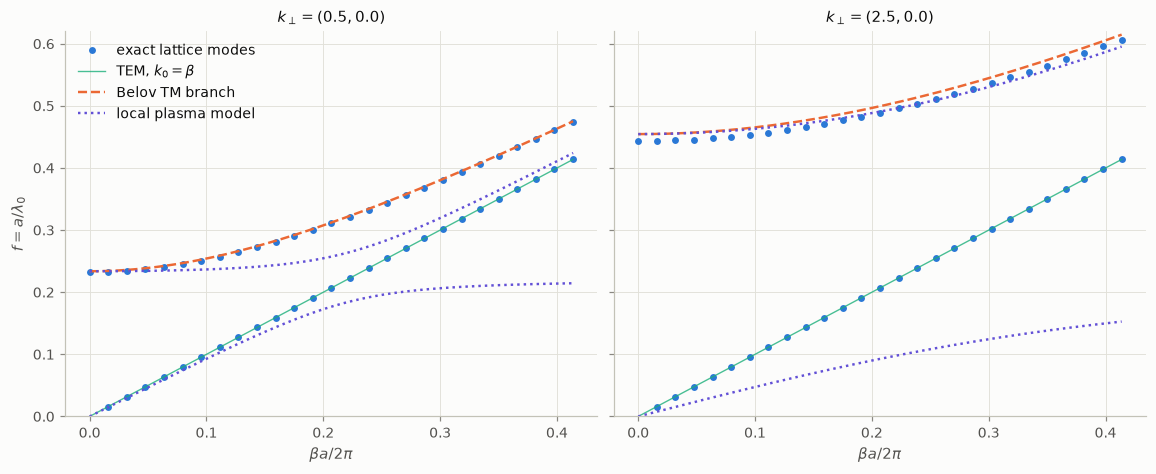

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(10.4, 4.2), sharey=True)
bb = np.linspace(0, 2.6, 200)
for a_, kp in zip(ax, KP_LIST):
    kp2v = kp[0] ** 2 + kp[1] ** 2
    xs = np.concatenate([[b] * len(r) for b, r in zip(bgrid, modes[kp])])
    ys = np.concatenate(modes[kp])
    a_.plot(xs / TWO_PI, ys / TWO_PI, "o", ms=3.5, color=CAT[0], label="exact lattice modes")
    a_.plot(bb / TWO_PI, bb / TWO_PI, "-", color=CAT[2], lw=0.9, alpha=0.8, label="TEM, $k_0=\\beta$")
    a_.plot(bb / TWO_PI, np.sqrt(kp2 + kp2v + bb**2) / TWO_PI, "--", color=CAT[1], label="Belov TM branch")
    lb = np.array([local_branches(b, kp2v) for b in bb])
    a_.plot(bb / TWO_PI, lb[:, 0] / TWO_PI, ":", color=CAT[6], label="local plasma model")
    a_.plot(bb / TWO_PI, lb[:, 1] / TWO_PI, ":", color=CAT[6])
    a_.set_xlabel("$\\beta a/2\\pi$"); a_.set_title(f"$k_\\perp=({kp[0]}, {kp[1]})$"); a_.set_ylim(0, 0.62)
ax[0].set_ylabel("$f=a/\\lambda_0$"); ax[0].legend(loc="upper left")
plt.show()

*Reading the figure.* The lattice has two branches in this range, the TEM line and the plasma-like one, for every $\mathbf k_\perp$ tested; the TM branch follows $\sqrt{k_p^2+k_\perp^2+\beta^2}$ to the printed deviation of Belov's form, which is at most about 2.5 percent, is larger at $k_\perp=2.5$ than at $0.5$, and falls with $\beta$ in the printed rows; that it comes from Belov's form being a long-wavelength limit (in $k_\perp a$) is a hypothesis, not tested here. The local plasma medium has two branches too, but they are not the lattice's: it has no exact TEM branch ($k_0=\beta$): its lower branch is within about 7 to 10 percent of the TEM line at $\beta=0.5$ and $1$ (printed) but flattens toward the plasma frequency at larger $\beta$, with no counterpart in the exact modes at $\beta=2$ (the printed case). Its upper branch is a different matter and depends on $k_\perp$: at $k_\perp=0.5$ it misses the exact TM branch by the printed 13 to 15 percent at $\beta=1$ and 2, while at $k_\perp=2.5$ it follows the TM branch to the printed 2 percent or so, comparable to Belov's form (better at $\beta=0.5$, $1$ and $2$, not at $\beta=2.6$); the assertions in the cell encode only the 10 percent miss at $k_\perp=0.5$ and the 3 percent bound at $k_\perp=2.5$. So the failure of the local plasma model is the missing TEM branch and the spurious flat branch, plus a TM branch that is wrong at small $k_\perp$, not a TM branch that is wrong everywhere. The mode count settles the general question: at fixed $k_0$ and $\mathbf k_\perp$ the model has three distinct $\beta^2$ (the TEM root at $\beta=k_0$, the plasma-like root and the ordinary wave of the model's $\varepsilon=\mathrm{diag}(1,1,\varepsilon_{zz})$, printed), while a local uniaxial $(\varepsilon,\mu)$ has one ordinary and one extraordinary wave, each linear in $\beta^2$, so at most two. No local uniaxial $(\varepsilon,\mu)$ reproduces the modes of the model at the two printed $k_0$ (2 and 3) and the one printed $\mathbf k_\perp=(0.5,0)$: there are three distinct $\beta^2$ against at most two. This is a count at those points, with the model's own ordinary wave as the third root, not a proof for every $a/\lambda$; it is a statement of mode counting, not of the radius of convergence.

**Drude wires: the TEM line becomes a slow wave that depends on $k_\perp$.** With a finite wire impedance $k_t^2$ is no longer a factor of $D$, and the long-wavelength model $\varepsilon_{zz}-1=1/[T-k_t^2/k_p^2]$ in $k_\perp^2=k_t^2\varepsilon_{zz}$ gives the dispersion relation $(k_\perp^2-k_t^2)(T-k_t^2/k_p^2)=k_t^2$, a quadratic in $k_t^2$ for fixed $T$: for $T=0$ its roots are $k_t=0$ and $k_t^2=k_\perp^2+k_p^2$, the two perfect-wire branches. The next cell finds the exact modes for collisionless Drude wires (exact impedance) and compares both roots with this relation.

In [16]:
print("Drude wires (collisionless, exact impedance): exact modes against (k_perp^2 - k_t^2)(T - k_t^2/k_p^2) = k_t^2")


def formula_roots(em, kperp2, beta, g):
    def F(k):
        T = (-1j * k * w.Zw_exact(k, R0, em(k))).real
        kt2 = k**2 - beta**2
        return (kperp2 - kt2) * (T - kt2 / kp2) - kt2
    v = np.array([F(k) for k in g])
    return np.array([brentq(F, g[i], g[i + 1]) for i in np.nonzero(v[:-1] * v[1:] < 0)[0]])


worst, ncase = 0.0, 0
for ratio in [0.3, 1.0, 3.0]:
    em = w.drude_k0(ratio / (TWO_PI * R0))
    for kp in [(0.2, 0.0), (0.5, 0.0)]:
        for beta in [0.5, 1.0]:
            g = np.linspace(0.02, 1.5 * beta + 0.3, 400)
            ex_ = w.find_modes_k0(beta, kp, R0, g, eps_m=em, exact=True)
            fo_ = formula_roots(em, kp[0] ** 2, beta, g)
            assert len(ex_) == len(fo_) and len(ex_) >= 1
            worst = max(worst, np.abs(ex_ / fo_ - 1).max())
            ncase += 1
            print(f"    r0/delta_s = {ratio}, k_perp = {kp[0]}, beta = {beta}: exact k0 = {np.round(ex_, 5)}, relation {np.round(fo_, 5)}, TEM-like k0/beta = {ex_[0] / beta:.4f}")
check(f"Drude modes against the generalized Silveirinha relation ({ncase} cases, relative, worst)", worst, 5e-3)
em1 = w.drude_k0(1.0 / (TWO_PI * R0))
k_a = w.find_modes_k0(1.0, (0.2, 0.0), R0, np.linspace(0.02, 1.8, 400), eps_m=em1, exact=True)[0]
k_b = w.find_modes_k0(1.0, (0.5, 0.0), R0, np.linspace(0.02, 1.8, 400), eps_m=em1, exact=True)[0]
print(f"    the slow-wave branch depends on k_perp (beta = 1, r0/delta_s = 1): k0 = {k_a:.4f} at k_perp = 0.2, {k_b:.4f} at 0.5; for perfect wires it is 1.0000 at both")
assert abs(k_a - k_b) > 0.02 and k_a < 1.0 and k_b < 1.0

Drude wires (collisionless, exact impedance): exact modes against (k_perp^2 - k_t^2)(T - k_t^2/k_p^2) = k_t^2


    r0/delta_s = 0.3, k_perp = 0.2, beta = 0.5: exact k0 = [0.42883 0.618  ], relation [0.42883 0.618  ], TEM-like k0/beta = 0.8577
    r0/delta_s = 0.3, k_perp = 0.2, beta = 1.0: exact k0 = [0.59757 1.02679], relation [0.59787 1.02679], TEM-like k0/beta = 0.5976


    r0/delta_s = 0.3, k_perp = 0.5, beta = 0.5: exact k0 = [0.34171 0.81178], relation [0.34169 0.81183], TEM-like k0/beta = 0.6834


    r0/delta_s = 0.3, k_perp = 0.5, beta = 1.0: exact k0 = [0.5539  1.14658], relation [0.55415 1.14658], TEM-like k0/beta = 0.5539
    r0/delta_s = 1.0, k_perp = 0.2, beta = 0.5: exact k0 = [0.49623], relation [0.49623], TEM-like k0/beta = 0.9925


    r0/delta_s = 1.0, k_perp = 0.2, beta = 1.0: exact k0 = [0.98971 1.33724], relation [0.98971 1.33825], TEM-like k0/beta = 0.9897


    r0/delta_s = 1.0, k_perp = 0.5, beta = 0.5: exact k0 = [0.4802], relation [0.4802], TEM-like k0/beta = 0.9604
    r0/delta_s = 1.0, k_perp = 0.5, beta = 1.0: exact k0 = [0.95177 1.43878], relation [0.95176 1.44034], TEM-like k0/beta = 0.9518


    r0/delta_s = 3.0, k_perp = 0.2, beta = 0.5: exact k0 = [0.49935], relation [0.49935], TEM-like k0/beta = 0.9987


    r0/delta_s = 3.0, k_perp = 0.2, beta = 1.0: exact k0 = [0.99863 1.61539], relation [0.99863 1.62077], TEM-like k0/beta = 0.9986
    r0/delta_s = 3.0, k_perp = 0.5, beta = 0.5: exact k0 = [0.49638], relation [0.49637], TEM-like k0/beta = 0.9928


    r0/delta_s = 3.0, k_perp = 0.5, beta = 1.0: exact k0 = [0.99247 1.68133], relation [0.99247 1.68795], TEM-like k0/beta = 0.9925
PASS  Drude modes against the generalized Silveirinha relation (12 cases, relative, worst): got 0.00392347, target 0, |diff| 3.92e-03 <= 5e-03


    the slow-wave branch depends on k_perp (beta = 1, r0/delta_s = 1): k0 = 0.9897 at k_perp = 0.2, 0.9518 at 0.5; for perfect wires it is 1.0000 at both


## 4. Metal wires: when does the nonlocality go away?

With $T=-ia^2k_0Z_w$ the generalized formula is $\varepsilon_{zz}-1=1/[T-(k_0^2-\beta^2)/k_p^2]$. For collisionless Drude wires and the thin impedance, $T=-k_0^2/K^2$ with $K^2=k_{pm}^2\eta_w=\pi r_0^2/\delta_s^2$ ($k_{pm}=1/\delta_s$), so

$$\varepsilon_{zz}-1=-\frac{1}{k_0^2/K^2+(k_0^2-\beta^2)/k_p^2}.$$

The first term of the denominator is the wire's kinetic inductance, the second the geometric inductance of the lattice, which carries the $\beta$ dependence. If $K^2\ll k_p^2$ the response is a local Drude response in $k_0$ alone; if $K^2\gg k_p^2$ and $\beta$ is not close to $k_0$ the wires act as perfect conductors and the full $\beta$ dependence remains. The ratio $\rho=K^2/k_p^2=\pi r_0^2/(k_p^2\delta_s^2)$ controls the $\beta$ dependence through the combination $\rho(1-\beta^2/k_0^2)$ (printed below), and with $\beta=0.9k_0$ the $\beta$ dependence saturates at a factor $1/0.19$ in $\varepsilon_{zz}-1$. This section quantifies it with the full model, using $\Delta=[\varepsilon_{zz}(\beta=0.9k_0)-1]/[\varepsilon_{zz}(\beta=0)-1]-1$ and the fraction $\phi=\Delta/\Delta_\infty$ of its perfect-conductor value $\Delta_\infty=1/0.19-1$. The thin impedance is accurate only for $r_0\ll\delta_s$; the exact one covers $r_0\gtrsim\delta_s$. The crossover is the value of $r_0/\delta_s$ at which $\phi=1/2$. The choice $\beta=0.9k_0$ is arbitrary and the crossover depends on it (printed below for several $\beta/k_0$); the first series is the one at $0.9$. The frequency is $f=0.05$ and $\mathbf k_\perp=(0.02,0)$; the series below varies $f_p$ at fixed $r_0$.

In [17]:
F4 = 0.05
K04 = TWO_PI * F4
KP4 = (0.02, 0.0)
DINF = 1 / 0.19 - 1


def phi_full(ratio, exact, r0=R0, f=F4, f_gamma_over_fp=0.0):
    fp = ratio / (TWO_PI * r0)
    em = w.drude(f, fp, f_gamma_over_fp * fp)
    k0 = TWO_PI * f
    e0 = w.eps_zz(k0, KP4, 0.0, r0, em, exact)
    e9 = w.eps_zz(k0, KP4, 0.9 * k0, r0, em, exact)
    return ((e9 - 1) / (e0 - 1) - 1) / DINF


def phi_formula(ratio, exact, r0=R0, f=F4):
    fp = ratio / (TWO_PI * r0)
    em = w.drude(f, fp)
    k0 = TWO_PI * f
    kp2r = w.kp2_model(r0)
    e0 = w.eps_silveirinha(k0, 0.0, r0, em, kp2r, exact)
    e9 = w.eps_silveirinha(k0, 0.9 * k0, r0, em, kp2r, exact)
    return ((e9 - 1) / (e0 - 1) - 1) / DINF


ratios = np.array([0.03, 0.1, 0.3, 0.5, 1, 2, 3, 10, 30, 100])
print("r0/delta_s   f_p     phi (thin Z)   phi (exact Z)   formula (exact Z)   thin-Z closed form 0.19 rho / (1 + 0.19 rho)")
ph_t = np.array([phi_full(r, False) for r in ratios])
ph_e = np.array([phi_full(r, True) for r in ratios])
ph_f = np.array([phi_formula(r, True) for r in ratios])
for r, a_, b_, c_ in zip(ratios, ph_t, ph_e, ph_f):
    rho = np.pi * R0**2 / ((R0 / r) ** 2 * kp2)
    print(f"  {r:7.2f}  {r / (TWO_PI * R0):7.2f}   {a_.real:10.4f}   {b_.real:10.4f}   {c_.real:12.4f}      {0.19 * rho / (1 + 0.19 * rho):10.4f}")
check("full model (thin Z) against the thin-Z closed form at r0/delta_s = 0.3 (phi)", ph_t[2].real, 5e-3, target=0.19 * (np.pi * R0**2 / ((R0 / 0.3) ** 2 * kp2)) / (1 + 0.19 * (np.pi * R0**2 / ((R0 / 0.3) ** 2 * kp2))))
check("full model against the generalized formula, exact Z (max |phi difference| over the series)", np.abs(ph_e - ph_f).max(), 2e-2)
check("the loss-free model is real: Im phi", np.abs(ph_e.imag).max(), 1e-9)
check("beta dependence saturates at the perfect-conductor value (phi at r0/delta_s = 100, exact Z)", ph_e[-1].real, 2e-2, target=1.0)
assert ph_e[0].real < 1e-2, "thin wires: no beta dependence"
assert np.all(np.diff(ph_e.real) > 0) and np.all(np.diff(ph_t.real) > 0)


def crossover(exact, r0=R0, f=F4):
    return brentq(lambda lr: phi_full(np.exp(lr), exact, r0, f).real - 0.5, np.log(0.05), np.log(50.0), xtol=1e-6)


cx_t, cx_e = np.exp(crossover(False)), np.exp(crossover(True))
cx_formula = np.exp(brentq(lambda lr: phi_formula(np.exp(lr), True).real - 0.5, np.log(0.05), np.log(50.0)))
cx_thin_closed = np.sqrt(kp2 * (1 / 0.19) / np.pi)
print(f"crossover r0/delta_s (phi = 1/2): thin Z {cx_t:.3f}, exact Z {cx_e:.3f}, generalized formula with exact Z {cx_formula:.3f}, thin-Z closed form sqrt(k_p^2 / (0.19 pi)) {cx_thin_closed:.3f}")
check("crossover: thin-Z full model against its closed form (relative)", cx_t / cx_thin_closed - 1, 0.03)
check("crossover: full model against the generalized formula, exact Z (relative)", cx_e / cx_formula - 1, 0.03)
print("crossover against wire radius (exact Z):")
cr = {}
for r0 in [0.003, 0.01, 0.03]:
    cr[r0] = np.exp(crossover(True, r0))
    print(f"    r0 = {r0}: k_p a = {np.sqrt(w.kp2_model(r0)):.3f}, crossover r0/delta_s = {cr[r0]:.3f}")
assert max(cr.values()) / min(cr.values()) < 1.7, "the crossover should depend on r0 only through k_p (logarithmically)"
print(f"    headline: crossover at r0/delta_s = {cx_e:.2f} (exact Z, r0 = 0.01), {cx_t:.2f} with the thin impedance")

r0/delta_s   f_p     phi (thin Z)   phi (exact Z)   formula (exact Z)   thin-Z closed form 0.19 rho / (1 + 0.19 rho)
     0.03     0.48       0.0003       0.0003         0.0003          0.0003
     0.10     1.59       0.0031       0.0031         0.0031          0.0031
     0.30     4.77       0.0274       0.0271         0.0271          0.0274
     0.50     7.96       0.0726       0.0706         0.0706          0.0726
     1.00    15.92       0.2386       0.2186         0.2184          0.2384
     2.00    31.83       0.5564       0.4667         0.4663          0.5560
     3.00    47.75       0.7386       0.6038         0.6034          0.7380
    10.00   159.15       0.9697       0.8565         0.8559          0.9690
    30.00   477.46       0.9972       0.9493         0.9486          0.9965
   100.00  1591.55       1.0004       0.9849         0.9842          0.9997
PASS  full model (thin Z) against the thin-Z closed form at r0/delta_s = 0.3 (phi): got 0.0274235, target 0.0273999, |diff|

crossover r0/delta_s (phi = 1/2): thin Z 1.786, exact Z 2.193, generalized formula with exact Z 2.196, thin-Z closed form sqrt(k_p^2 / (0.19 pi)) 1.787
PASS  crossover: thin-Z full model against its closed form (relative): got -0.000792945, target 0, |diff| 7.93e-04 <= 3e-02
PASS  crossover: full model against the generalized formula, exact Z (relative): got -0.00111567, target 0, |diff| 1.12e-03 <= 3e-02
crossover against wire radius (exact Z):
    r0 = 0.003: k_p a = 1.182, crossover r0/delta_s = 1.777
    r0 = 0.01: k_p a = 1.381, crossover r0/delta_s = 2.193
    r0 = 0.03: k_p a = 1.690, crossover r0/delta_s = 2.959
    headline: crossover at r0/delta_s = 2.19 (exact Z, r0 = 0.01), 1.79 with the thin impedance


In [18]:
from scipy.special import iv
print("skin effect raises the kinetic reactance: Z_w exact / thin against y I0(y) / (2 I1(y)), y = r0/delta_s")
worst_z = 0.0
for yv in [0.3, 1.0, 2.0, 3.0, 10.0]:
    em_ = w.drude(F4, yv / (TWO_PI * R0))
    zr = (w.Zw_exact(K04, R0, em_) / w.Zw_thin(K04, R0, em_)).real
    worst_z = max(worst_z, abs(zr / (yv * iv(0, yv) / (2 * iv(1, yv))) - 1))
    print(f"    r0/delta_s = {yv}: Z_w exact / thin = {zr:.4f}, closed form {yv * iv(0, yv) / (2 * iv(1, yv)):.4f}")
check("Z_w exact / thin against y I0(y) / (2 I1(y)) (relative, worst of 5)", worst_z, 5e-3)

print("crossover depends on beta/k0 (phi defined with the perfect-wire value 1/(1 - x^2) - 1 at x = beta/k0), f = 0.05, k_perp = (0.02, 0), r0 = 0.01")


def phi_x(ratio, exact, x):
    em = w.drude(F4, ratio / (TWO_PI * R0))
    e0 = w.eps_zz(K04, KP4, 0.0, R0, em, exact)
    e1 = w.eps_zz(K04, KP4, x * K04, R0, em, exact)
    return (((e1 - 1) / (e0 - 1) - 1) / (1 / (1 - x**2) - 1)).real


cx_x = {}
for x in [0.3, 0.5, 0.9, 0.97, 0.99]:
    ct_ = np.exp(brentq(lambda lr: phi_x(np.exp(lr), False, x) - 0.5, np.log(0.05), np.log(60.0), xtol=1e-6))
    ce_ = np.exp(brentq(lambda lr: phi_x(np.exp(lr), True, x) - 0.5, np.log(0.05), np.log(60.0), xtol=1e-6))
    cc_ = np.sqrt(kp2 / (np.pi * (1 - x**2)))
    cx_x[x] = (ct_, ce_, cc_)
    print(f"    beta/k0 = {x}: crossover r0/delta_s thin Z {ct_:.3f}, exact Z {ce_:.3f}, thin-Z closed form sqrt(k_p^2 / (pi (1 - x^2))) {cc_:.3f}")
    check(f"crossover at beta/k0 = {x}: thin-Z full model against its closed form (relative)", ct_ / cc_ - 1, 5e-3)
assert cx_x[0.5][1] < cx_x[0.9][1] < cx_x[0.97][1] < cx_x[0.99][1] and cx_x[0.99][1] > 10 * cx_x[0.5][1]
check("crossover at beta/k0 = 0.9 agrees with the one printed above (exact Z, relative)", cx_x[0.9][1] / cx_e - 1, 1e-4)
print("    criterion: rho (1 - beta^2/k0^2) of order one, with rho = pi r0^2 / (k_p^2 delta_s^2); near the TEM pole beta -> k0 thick wires are needed")

print("finite kinetic reactance caps the enhancement at beta = k0: [eps(k0) - 1] / [eps(0) - 1] against 1 + rho (thin Z, formula) and the full model at beta = 0.999 k0")
worst_cap = 0.0
for yv in [0.3, 1.0, 3.0]:
    em_ = w.drude(F4, yv / (TWO_PI * R0))
    rho_ = np.pi * R0**2 / ((R0 / yv) ** 2 * kp2)
    e0f = w.eps_zz(K04, KP4, 0.0, R0, em_)
    ef = w.eps_zz(K04, KP4, 0.999 * K04, R0, em_)
    es = w.eps_silveirinha(K04, K04, R0, em_, kp2)
    cap_formula = ((es - 1) / (e0f - 1)).real
    worst_cap = max(worst_cap, abs(cap_formula / (1 + rho_) - 1))
    print(f"    r0/delta_s = {yv}: rho = {rho_:.3f}, 1 + rho = {1 + rho_:.3f}, formula at beta = k0 {cap_formula:.3f}, full model at 0.999 k0 {((ef - 1) / (e0f - 1)).real:.3f}")
check("enhancement at beta = k0 against 1 + rho (relative, worst of 3)", worst_cap, 5e-3)

print("radius of convergence of the beta series for Drude wires (thin Z): c_n / c_(n-2) times k0^2 against 1 / (1 + 1/rho), i.e. pole at beta^2 = k0^2 (1 + 1/rho)")
worst_pole = 0.0
for yv in [0.3, 1.0, 3.0]:
    em_ = w.drude(F4, yv / (TWO_PI * R0))
    rho_ = np.pi * R0**2 / ((R0 / yv) ** 2 * kp2)
    cdr = w.taylor(lambda b: w.eps_zz(K04, KP4, b, R0, em_), 0.5 * K04, n=32, orders=range(0, 13))
    rat = (cdr[12] / cdr[10]).real * K04**2
    worst_pole = max(worst_pole, abs(rat / (1 / (1 + 1 / rho_)) - 1))
    print(f"    r0/delta_s = {yv}: rho = {rho_:.3f}, radius from c12/c10 = {1 / np.sqrt(rat):.3f} k0, formula k0 sqrt(1 + 1/rho) = {np.sqrt(1 + 1 / rho_):.3f} k0")
check("Drude pole position from Taylor coefficients against k0 sqrt(1 + 1/rho) (c12/c10 k0^2, relative, worst of 3)", worst_pole, 2e-2)

skin effect raises the kinetic reactance: Z_w exact / thin against y I0(y) / (2 I1(y)), y = r0/delta_s
    r0/delta_s = 0.3: Z_w exact / thin = 1.0112, closed form 1.0112
    r0/delta_s = 1.0: Z_w exact / thin = 1.1201, closed form 1.1201
    r0/delta_s = 2.0: Z_w exact / thin = 1.4331, closed form 1.4331
    r0/delta_s = 3.0: Z_w exact / thin = 1.8519, closed form 1.8519
    r0/delta_s = 10.0: Z_w exact / thin = 5.2709, closed form 5.2709
PASS  Z_w exact / thin against y I0(y) / (2 I1(y)) (relative, worst of 5): got 1.21095e-06, target 0, |diff| 1.21e-06 <= 5e-03
crossover depends on beta/k0 (phi defined with the perfect-wire value 1/(1 - x^2) - 1 at x = beta/k0), f = 0.05, k_perp = (0.02, 0), r0 = 0.01
    beta/k0 = 0.3: crossover r0/delta_s thin Z 0.816, exact Z 0.851, thin-Z closed form sqrt(k_p^2 / (pi (1 - x^2))) 0.817
PASS  crossover at beta/k0 = 0.3: thin-Z full model against its closed form (relative): got -0.00105369, target 0, |diff| 1.05e-03 <= 5e-03
    beta/k0 = 0.5: cros

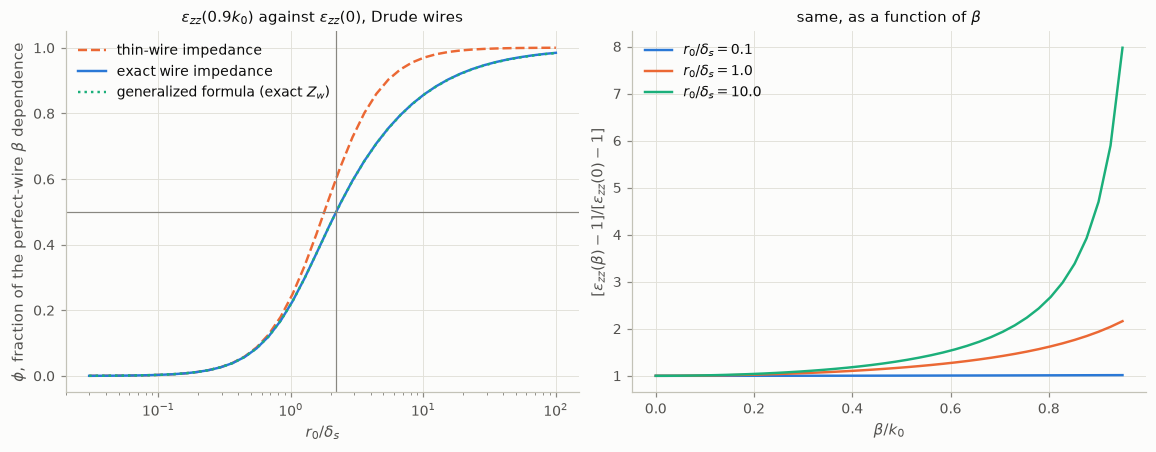

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(10.4, 4.0))
rr = np.geomspace(0.03, 100, 40)
ax[0].semilogx(rr, [phi_full(r, False).real for r in rr], "--", color=CAT[1], label="thin-wire impedance")
ax[0].semilogx(rr, [phi_full(r, True).real for r in rr], color=CAT[0], label="exact wire impedance")
ax[0].semilogx(rr, [phi_formula(r, True).real for r in rr], ":", color=CAT[2], label="generalized formula (exact $Z_w$)")
ax[0].axhline(0.5, color=MUTED, lw=0.8); ax[0].axvline(cx_e, color=MUTED, lw=0.8)
ax[0].set_xlabel("$r_0/\\delta_s$"); ax[0].set_ylabel("$\\phi$, fraction of the perfect-wire $\\beta$ dependence")
ax[0].set_title("$\\varepsilon_{zz}(0.9k_0)$ against $\\varepsilon_{zz}(0)$, Drude wires"); ax[0].legend(loc="upper left")
bs4 = np.linspace(0, 0.95, 40) * K04
for ratio, col in [(0.1, CAT[0]), (1.0, CAT[1]), (10.0, CAT[2])]:
    em = w.drude(F4, ratio / (TWO_PI * R0))
    ee = np.array([w.eps_zz(K04, KP4, b, R0, em, True).real for b in bs4])
    ax[1].plot(bs4 / K04, (ee - 1) / (ee[0] - 1), color=col, label=f"$r_0/\\delta_s={ratio}$")
ax[1].set_xlabel("$\\beta/k_0$"); ax[1].set_ylabel("$[\\varepsilon_{zz}(\\beta)-1]/[\\varepsilon_{zz}(0)-1]$")
ax[1].set_title("same, as a function of $\\beta$"); ax[1].legend()
plt.show()

*What the series shows.* The $\beta$ dependence is nearly absent for wires thin against the skin depth and approaches its perfect-wire value only for wires thick against it, with the crossover where the kinetic reactance $T$ of the wire equals the geometric term $k_t^2/k_p^2$ that carries the $\beta$ dependence. That is $\rho(1-\beta^2/k_0^2)$ of order one, i.e. $r_0/\delta_s$ of order $\sqrt{k_p^2/[\pi(1-\beta^2/k_0^2)]}$ (the thin-Z closed form, checked in the printed table), which is of order one (printed) for $\beta$ up to about $0.9k_0$ and grows steeply near the TEM pole: with exact $Z_w$ the printed crossover rises from about $0.95$ at $0.5k_0$ and $2.2$ at $0.9k_0$ to $5.7$ at $0.97k_0$ and $15.7$ at $0.99k_0$, more than ten times its $0.5k_0$ value. A finite kinetic reactance also caps the enhancement at $\beta=k_0$ at the finite value $1+\rho$ instead of infinity (printed). Using the thin impedance overestimates the nonlocality, because uniform current ignores the skin effect, which *raises* the wire's kinetic reactance at $r_0\gtrsim\delta_s$ (the current crowds into an area of about $2\pi r_0\delta_s$ rather than $\pi r_0^2$; the printed ratio $Z_w^{\rm exact}/Z_w^{\rm thin}$ is above one and follows $y I_0(y)/[2I_1(y)]$, $y=r_0/\delta_s$) and so reduces the $\beta$ dependence (the printed difference of the two series). For Drude wires the pole of $\varepsilon_{zz}$ in $\beta$ moves from $k_0$ to $k_0\sqrt{1+1/\rho}$ (printed Taylor-coefficient check), so the radius of convergence $k_0$ of section 2 belongs to perfect wires. For a given metal and period the criterion is read off by comparing the wire radius with $\delta_s$; well below it (printed $\phi=0.003$ at $r_0/\delta_s=0.1$, $0.07$ at $0.5$, $0.22$ at $1$) the lattice behaves, in this model, as a local plasma in $\omega$; the dependence nears its perfect-wire value only for $r_0/\delta_s$ of order $10$ to $100$ (the series above is collisionless, so it does not say how much loss changes the numbers).

**Hypothesis, not tested here.** Metal rods in the plane (notebook 06) have a magnetic response whose strength is set by the same comparison, the rod size against the skin depth. The wire result suggests that the size scaling of metal magnetism and the loss of wire-medium nonlocality at optical frequencies are the same competition between the kinetic reactance of the metal and a geometric (lattice) term. Notebook 07 does not compute the magnetic case, so this is an expectation to test, not a result.

## 5. Summary

- A thin-wire model on the lattice sums of `rodlattice.py`, continued to imaginary $k_t$, reproduces everything it was checked against: brute-force lattice sums at imaginary $k_t$, a real $\varepsilon_{zz}$ for lossless wires, the averaged Maxwell equation, Belov's plasma wave number with the constant of the formula (found equal to the Dedekind-eta value $\ln[4\pi^{3/2}/\Gamma(1/4)^2]$ to the printed tolerance), Silveirinha's formula for metal wires, and the full multipole solver at $\beta=0$ (to the printed value at $R=0.02$, shrinking faster than $R^2$).
- For perfect wires $\varepsilon_{zz}(\omega,\mathbf k)$ has a pole at $\beta=k_0$, and the printed ratios of Taylor coefficients in $\beta^2$ are $k_0^{-2}$ to $10^{-4}$: the radius of convergence is $k_0$ at any $k_0a$ (for Drude wires $k_0\sqrt{1+1/\rho}$). The local plasma description is therefore accurate to $(\beta/k_0)^2$ and fails for $\beta$ not small against $k_0$, at any $a/\lambda$; that no local uniaxial $(\varepsilon,\mu)$ reproduces the modes follows from the mode count of section 3 at the printed points, not from the radius. The $\beta^2$ coefficient is the plasma term $-k_p^2/k_0^4$. The $k_\perp^2$ coefficient is smaller by the printed ratio and has the form of a permeability only at $\beta=0$: for $\beta\neq0$ a permeability would need partner terms in $\varepsilon_{xx}$, $\varepsilon_{yy}$ and $\varepsilon_{xz}$ that the model does not have, so it is non-magnetic axial-current dispersion. Neither second-order coefficient of $\varepsilon_{zz}$ (in $\beta^2$ or in $k_\perp^2$) is a permeability once $\beta\neq0$ in this model.
- The exact modes are a TEM line $k_0=\beta$ (to $10^{-9}$, for every $\mathbf k_\perp$) and the plasma-like branch, which follows $\sqrt{k_p^2+k_\perp^2+\beta^2}$ to the printed deviation. The local plasma model lacks the TEM branch and has a spurious flat branch near the plasma frequency; its upper branch misses the TM branch at small $k_\perp$ but follows it to the printed few percent at $k_\perp=2.5$. No local uniaxial $(\varepsilon,\mu)$ can reproduce them, since there are three $\beta^2$ roots at given $(k_0,\mathbf k_\perp)$ against at most two. For Drude wires the TEM line becomes a slow wave that depends on $k_\perp$, and the printed modes follow the dispersion relation of Silveirinha's form to the printed tolerance.
- For Drude wires the $\beta$ dependence is nearly absent for $r_0$ well below the skin depth (printed $\phi=0.003$ at $r_0/\delta_s=0.1$) and approaches the perfect-wire value only well above it ($\phi=0.86$ at 10 and $0.98$ at 100, exact $Z_w$, $\beta=0.9k_0$); the crossover $\phi=1/2$ is at $r_0/\delta_s$ of order one (2.2 for exact $Z_w$) and depends on $\beta$: the criterion is $\rho(1-\beta^2/k_0^2)$ of order one, so thick wires are needed near the TEM pole, where a finite kinetic reactance caps the enhancement at $1+\rho$ (thin impedance, as printed; the exact impedance was not checked for the cap or the pole).

## 6. Caveats and open ends

- **Thin-wire model, $m=0$ only.** Each wire is a uniform axial surface current. Transverse currents and higher multipoles are absent, so the wires have no transverse polarizability or magnetic response. The missing $m=\pm1$ term changes the $k_\perp^2$ coefficient on which the permeability discussion of section 2 rests by the printed several percent (cell (e''); quote $c_\perp$ and $\mu_\perp-1$ to two digits only). The multipole check holds at $\beta=0$ for $R\le0.02$ and $k_\perp\le0.71$ in the first table, and to the printed errors up to the zone edge at $R=0.01$ (cell (e')), where the $m=0$ error grows with $k_\perp$ and $R$ (up to the printed 8 percent at $R=0.05$ and 22 percent at $R=0.1$ for $k_x=3$); it says nothing about frequencies near the lattice's own resonances. The TEM line follows from the factor $k_t^2$ of $D$ for perfect wires in this model. Whether the $\beta$ dependence and the modes at $R=0.01$ are affected by the missing $m\neq0$ terms is not tested, since no second solver with $\beta\neq0$ is used. The checks at $\beta\neq0$ rest on the model's internal consistency, Belov's and Silveirinha's formulas and the $\beta=0$ comparison, not on a second full solver with $\beta\neq0$.
- **Exact impedance** takes $k_m=k_0\sqrt{\varepsilon_m}$ inside the metal (no $\beta^2$) and a field outside that depends on the total current only. Both are good for $k_tr_0\ll1$ and $|\varepsilon_m|\gg1$; sections 1(d) and 1(e) test them for $|\varepsilon_m|$ from 3 to $10^6$ but not for $\beta$ comparable to $k_0\sqrt{|\varepsilon_m|}$. Drude wires here are collisionless; loss enters through a complex $\varepsilon_m$ in `wires.eps_zz` and was spot-checked only at $\beta=0$ (cell (e), $\varepsilon_m=-10^6+10^3i$, finite with positive imaginary part), not at $\beta\neq0$, and not studied.
- **No slab, so no additional boundary condition.** A finite wire medium needs one (the current vanishes at the ends or interface, Silveirinha's ABC), which no bulk quantity here fixes; nothing in this notebook says how reflection from a wire-medium slab would behave.
- **Branch count.** Only modes with $k_t$ below the diffraction onset, $f\le0.67$ and $\beta a/2\pi\le0.41$, were scanned; there the $m=0$ model has two branches, but the higher bands of the real lattice, with $m\neq0$, are not represented.
- The statement that the local plasma model has a lower branch is a statement about the model $\varepsilon_{zz}=1-k_p^2/k_0^2$ with $\varepsilon_\perp=1$; the statement that it is not what the lattice does is a comparison of the printed numbers (the flat branch at $\beta=2$ and $k_\perp=0.5$ only; the upper branch at four values of $\beta$ for $k_\perp=0.5$ and $2.5$).
- The link to the size scaling of metal magnetism in notebook 06 is a hypothesis.

## 7. References

- P. A. Belov, R. Marques, S. I. Maslovski, I. S. Nefedov, M. Silveirinha, C. R. Simovski, S. A. Tretyakov, "Strong spatial dispersion in wire media in the very large wavelength limit", Phys. Rev. B 67, 113103 (2003) (checked 2026-11-23; the formulas used are not in its abstract and were not checked against its text).
- M. G. Silveirinha, "Nonlocal homogenization model for a periodic array of epsilon-negative rods", Phys. Rev. E 73, 046612 (2006) (checked 2026-11-23).
- J. B. Pendry, A. J. Holden, W. J. Stewart, I. Youngs, "Extremely low frequency plasmons in metallic mesostructures", Phys. Rev. Lett. 76, 4773 (1996) (checked 2026-11-23).
- C. R. Simovski, P. A. Belov, A. V. Atrashchenko, Y. S. Kivshar, "Wire metamaterials: physics and applications", Adv. Mater. 24, 4229 (2012) (checked 2026-11-23).

In [20]:
print(f"total run time {time.perf_counter() - T0:.0f} s")

total run time 7 s
